# Approach 2: SuperSynth ventricles pasted on nxbsimplified labels

Visualizes `add_csf_supersynth.py` (TODO.txt, approach 2). Synthetic images generated from the nxbsimplified
labels were segmented with SuperSynth (`data/inputs/supersynth`, FreeSurfer labels, 0.4 mm). Here:

**Ventricles (label 50)**: SuperSynth ventricles (4/43 lateral, 5/44 inferior lateral, 14 3rd, 15 4th) → resampled to the
0.2 mm label grid → dilated a bit → pasted on the segmentation, removing everything already occupied by tissue.

**CSF (label 24)**: SuperSynth CSF pasted directly, minus tissue. *The current SuperSynth outputs contain no CSF label, so no
CSF is added yet.*

Outputs come from:
```
cd supersynth_approach
python add_csf_supersynth.py --save-intermediates
```
The last section compares the ventricles with the morphological approach (`data/outputs/morphological_approach`).

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np
import pandas as pd
from matplotlib.patches import Patch
from scipy import ndimage as ndi

ROOT = Path.cwd().parent  # add_csf_to_labels/ (shared data/)
IN_DIR = ROOT / "data" / "inputs" / "nxbsimplified" / "labels"
SS_DIR = ROOT / "data" / "inputs" / "supersynth"
OUT_DIR = ROOT / "data" / "outputs" / "supersynth_approach"
MORPH_DIR = ROOT / "data" / "outputs" / "morphological_approach" / "labels"
summary = json.load(open(OUT_DIR / "summary.json"))
P = summary["params"]
VENT, CSF = P["ventricle_label"], P["csf_label"]
CASES = [c["case"] for c in summary["cases"]]
print(json.dumps(P, indent=1))
display(pd.DataFrame(summary["cases"]).set_index("case").round(2))

{
 "ss_ventricle_labels": [
  4,
  5,
  43,
  44,
  14,
  15
 ],
 "ss_csf_labels": [
  24
 ],
 "dilate_mm_r": 0.6,
 "ventricle_label": 50,
 "csf_label": 24
}


,ss_ventricle_labels_found,ss_csf_labels_found,ss_ventricle_cm3,ss_ventricle_on_tissue_cm3,ventricle_cm3,csf_cm3,seconds
case,,,,,,,
case-1,"[14, 15, 43, 44]",[],9.71,1.38,9.19,0.0,28.8
case-2,"[14, 15, 43, 44]",[],15.71,1.83,14.68,0.0,27.7
case-3,"[14, 15, 43, 44]",[],17.24,2.16,16.12,0.0,49.3
case-4,"[4, 5, 14, 15]",[],16.28,2.41,14.87,0.0,38.6
case-5,"[4, 5, 14, 15]",[],13.03,2.02,11.87,0.0,26.3


In [2]:
CORTEX = (3, 595, 597)
COLORS = {
    "cortex (3, 595, 597)": (0.88, 0.40, 0.40),
    "forebrain WM (7)": (0.93, 0.93, 0.93),
    "other tissue": (0.35, 0.58, 0.85),
    f"ventricle ({VENT})": (1.00, 0.82, 0.00),
    f"CSF ({CSF})": (0.20, 0.75, 0.35),
}

def colorize(s):
    rgb = np.zeros(s.shape + (3,))
    rgb[s > 0] = COLORS["other tissue"]
    rgb[np.isin(s, CORTEX)] = COLORS["cortex (3, 595, 597)"]
    rgb[s == 7] = COLORS["forebrain WM (7)"]
    rgb[s == VENT] = COLORS[f"ventricle ({VENT})"]
    rgb[s == CSF] = COLORS[f"CSF ({CSF})"]
    return rgb

# SuperSynth (FreeSurfer) labels, coarse classes
SS_CLASSES = [
    ("SS cortex (3/42, 8/47)", (3, 42, 8, 47), (0.88, 0.40, 0.40)),
    ("SS WM (2/41, 7/46, 16, 77)", (2, 41, 7, 46, 16, 77), (0.93, 0.93, 0.93)),
    ("SS ventricles (4/43, 5/44, 14, 15)", tuple(P["ss_ventricle_labels"]), (1.00, 0.82, 0.00)),
    ("SS CSF (24)", tuple(P["ss_csf_labels"]), (0.20, 0.75, 0.35)),
]

def colorize_ss(s):
    rgb = np.zeros(s.shape + (3,))
    rgb[s > 0] = COLORS["other tissue"]
    for _, labs, c in SS_CLASSES:
        rgb[np.isin(s, labs)] = c
    return rgb

def overlay(s, mask, color, alpha=0.75):
    rgb = np.repeat((0.25 + 0.35 * (s > 0))[..., None], 3, -1)
    rgb[np.isin(s, CORTEX)] *= 0.75
    rgb[mask] = (1 - alpha) * rgb[mask] + alpha * np.array(color)
    return rgb

def take(vol, axis, idx):
    return np.take(vol, idx, axis=axis).T

VIEW = {0: "sagittal", 1: "coronal", 2: "axial"}

def show(ax, img, title):
    ax.imshow(img, origin="lower", interpolation="nearest")
    ax.set_title(title, fontsize=10)
    ax.axis("off")

def legend(fig, items):
    fig.legend(handles=[Patch(color=c, label=k) for k, c in items], loc="lower center",
               ncol=len(items), frameon=False, fontsize=10)

def ss_on_label_grid(case, shape, affine):
    """SuperSynth segmentation resampled (nearest) on the 0.2 mm label grid, for display"""
    im = nib.load(SS_DIR / f"{case}.nii.gz")
    m = np.linalg.inv(im.affine) @ affine
    ss = np.rint(np.asarray(im.dataobj)).astype(np.int16)
    return ndi.affine_transform(ss, m[:3, :3], m[:3, 3], output_shape=shape, order=0)

def load_case(case):
    img = nib.load(IN_DIR / f"{case}.nii.gz")
    d = {"input": np.asarray(img.dataobj),
         "output": np.asarray(nib.load(OUT_DIR / "labels" / f"{case}.nii.gz").dataobj),
         "morph": np.asarray(nib.load(MORPH_DIR / f"{case}.nii.gz").dataobj) == VENT}
    d["ss"] = ss_on_label_grid(case, d["input"].shape, img.affine)
    for f in sorted((OUT_DIR / "intermediates" / case).glob("*.nii.gz")):
        d[f.name.replace(".nii.gz", "")] = np.asarray(nib.load(f).dataobj).astype(bool)
    d["vox_cm3"] = float(np.prod(img.header.get_zooms()[:3])) / 1000
    return d

def ventricle_slices(vent):
    return [int(np.median(i)) for i in np.nonzero(vent)]

In [3]:
def plot_process(case, d):
    sl = ventricle_slices(d["ventricles"])
    steps = [
        ("1. input labels", lambda a, k: colorize(take(d["input"], a, k))),
        ("2. SuperSynth seg", lambda a, k: colorize_ss(take(d["ss"], a, k))),
        ("3. SS ventricles (resampled)", lambda a, k: overlay(take(d["input"], a, k), take(d["ss_ventricles"], a, k), (0.6, 0.3, 0.9))),
        (f"4. dilated {P['dilate_mm_r']} mm", lambda a, k: overlay(take(d["input"], a, k), take(d["ss_ventricles_dilated"], a, k), (0.9, 0.55, 0.1))),
        ("5. minus tissue = ventricles", lambda a, k: overlay(take(d["input"], a, k), take(d["ventricles"], a, k), COLORS[f"ventricle ({VENT})"])),
        ("6. output labels", lambda a, k: colorize(take(d["output"], a, k))),
    ]
    fig, axes = plt.subplots(3, len(steps), figsize=(3.4 * len(steps), 3 * 3.5))
    for r, axis in enumerate([0, 1, 2]):
        for c, (title, f) in enumerate(steps):
            show(axes[r, c], f(axis, sl[axis]), title if r == 0 else "")
        axes[r, 0].text(-0.05, 0.5, f"{VIEW[axis]} {sl[axis]}", transform=axes[r, 0].transAxes,
                        rotation=90, va="center", ha="right", fontsize=11)
    legend(fig, [(n, c) for n, _, c in SS_CLASSES[:3]] + [("SS other tissue", COLORS["other tissue"])])
    fig.suptitle(f"{case}: process (slices through the ventricle centre)", fontsize=14)
    plt.tight_layout(rect=(0, 0.03, 1, 1))
    plt.show()

def plot_zoom(case, d, half=60):
    """zoom around the ventricle: input, SuperSynth, output, and comparison with the morphological approach"""
    sl = ventricle_slices(d["ventricles"])
    fig, axes = plt.subplots(3, 4, figsize=(17, 13))
    for r, axis in enumerate([0, 1, 2]):
        o = [a for a in range(3) if a != axis]
        win = [slice(max(sl[a] - 2 * half, 0), sl[a] + 2 * half) for a in o]
        crop = lambda v: take(v, axis, sl[axis])[win[1], win[0]]
        inp, ss_v, mo_v = crop(d["input"]), crop(d["ventricles"]), crop(d["morph"])
        cmp_ = np.repeat((0.25 + 0.35 * (inp > 0))[..., None], 3, -1)
        cmp_[ss_v & mo_v] = (1.0, 0.82, 0.0)
        cmp_[ss_v & ~mo_v] = (0.85, 0.2, 0.6)
        cmp_[~ss_v & mo_v] = (0.1, 0.7, 0.8)
        show(axes[r, 0], colorize(inp), f"{VIEW[axis]} {sl[axis]}: input")
        show(axes[r, 1], colorize_ss(crop(d["ss"])), "SuperSynth")
        show(axes[r, 2], colorize(crop(d["output"])), "output")
        show(axes[r, 3], cmp_, "ventricles: supersynth vs morphological")
    legend(fig, [("both", (1.0, 0.82, 0.0)), ("supersynth only", (0.85, 0.2, 0.6)),
                 ("morphological only", (0.1, 0.7, 0.8))])
    fig.suptitle(f"{case}: zoom around the ventricle (±24 mm)", fontsize=13)
    plt.tight_layout(rect=(0, 0.03, 1, 1))
    plt.show()

def plot_result(case, d, fracs=(0.35, 0.5, 0.65)):
    idx = np.nonzero(d["output"] > 0)
    lo = [i.min() for i in idx]; hi = [i.max() for i in idx]
    fig, axes = plt.subplots(3, 2 * len(fracs), figsize=(3.6 * 2 * len(fracs), 3 * 3.6))
    for r, axis in enumerate([0, 1, 2]):
        for j, f in enumerate(fracs):
            k = int(lo[axis] + f * (hi[axis] - lo[axis]))
            show(axes[r, 2 * j], colorize(take(d["input"], axis, k)), f"{VIEW[axis]} {k}: input")
            show(axes[r, 2 * j + 1], colorize(take(d["output"], axis, k)), f"{VIEW[axis]} {k}: output")
    legend(fig, list(COLORS.items()))
    fig.suptitle(f"{case}: input vs output", fontsize=14)
    plt.tight_layout(rect=(0, 0.03, 1, 1))
    plt.show()

def stats(case, d):
    v, m = d["ventricles"], d["morph"]
    inter = (v & m).sum()
    return {"case": case,
            "supersynth ventricle (cm3)": v.sum() * d["vox_cm3"],
            "morphological ventricle (cm3)": m.sum() * d["vox_cm3"],
            "dice": 2 * inter / (v.sum() + m.sum()),
            "supersynth only (cm3)": (v & ~m).sum() * d["vox_cm3"],
            "morphological only (cm3)": (m & ~v).sum() * d["vox_cm3"]}

## Per-case process and results

For each case: (a) every step on slices through the ventricle centre; (b) a zoom with the SuperSynth segmentation and the comparison with the morphological ventricles; (c) input vs output at three positions per view.

### case-1

{'case': 'case-1', 'supersynth ventricle (cm3)': np.float64(9.193), 'morphological ventricle (cm3)': np.float64(9.19), 'dice': np.float64(0.905), 'supersynth only (cm3)': np.float64(0.873), 'morphological only (cm3)': np.float64(0.87)}


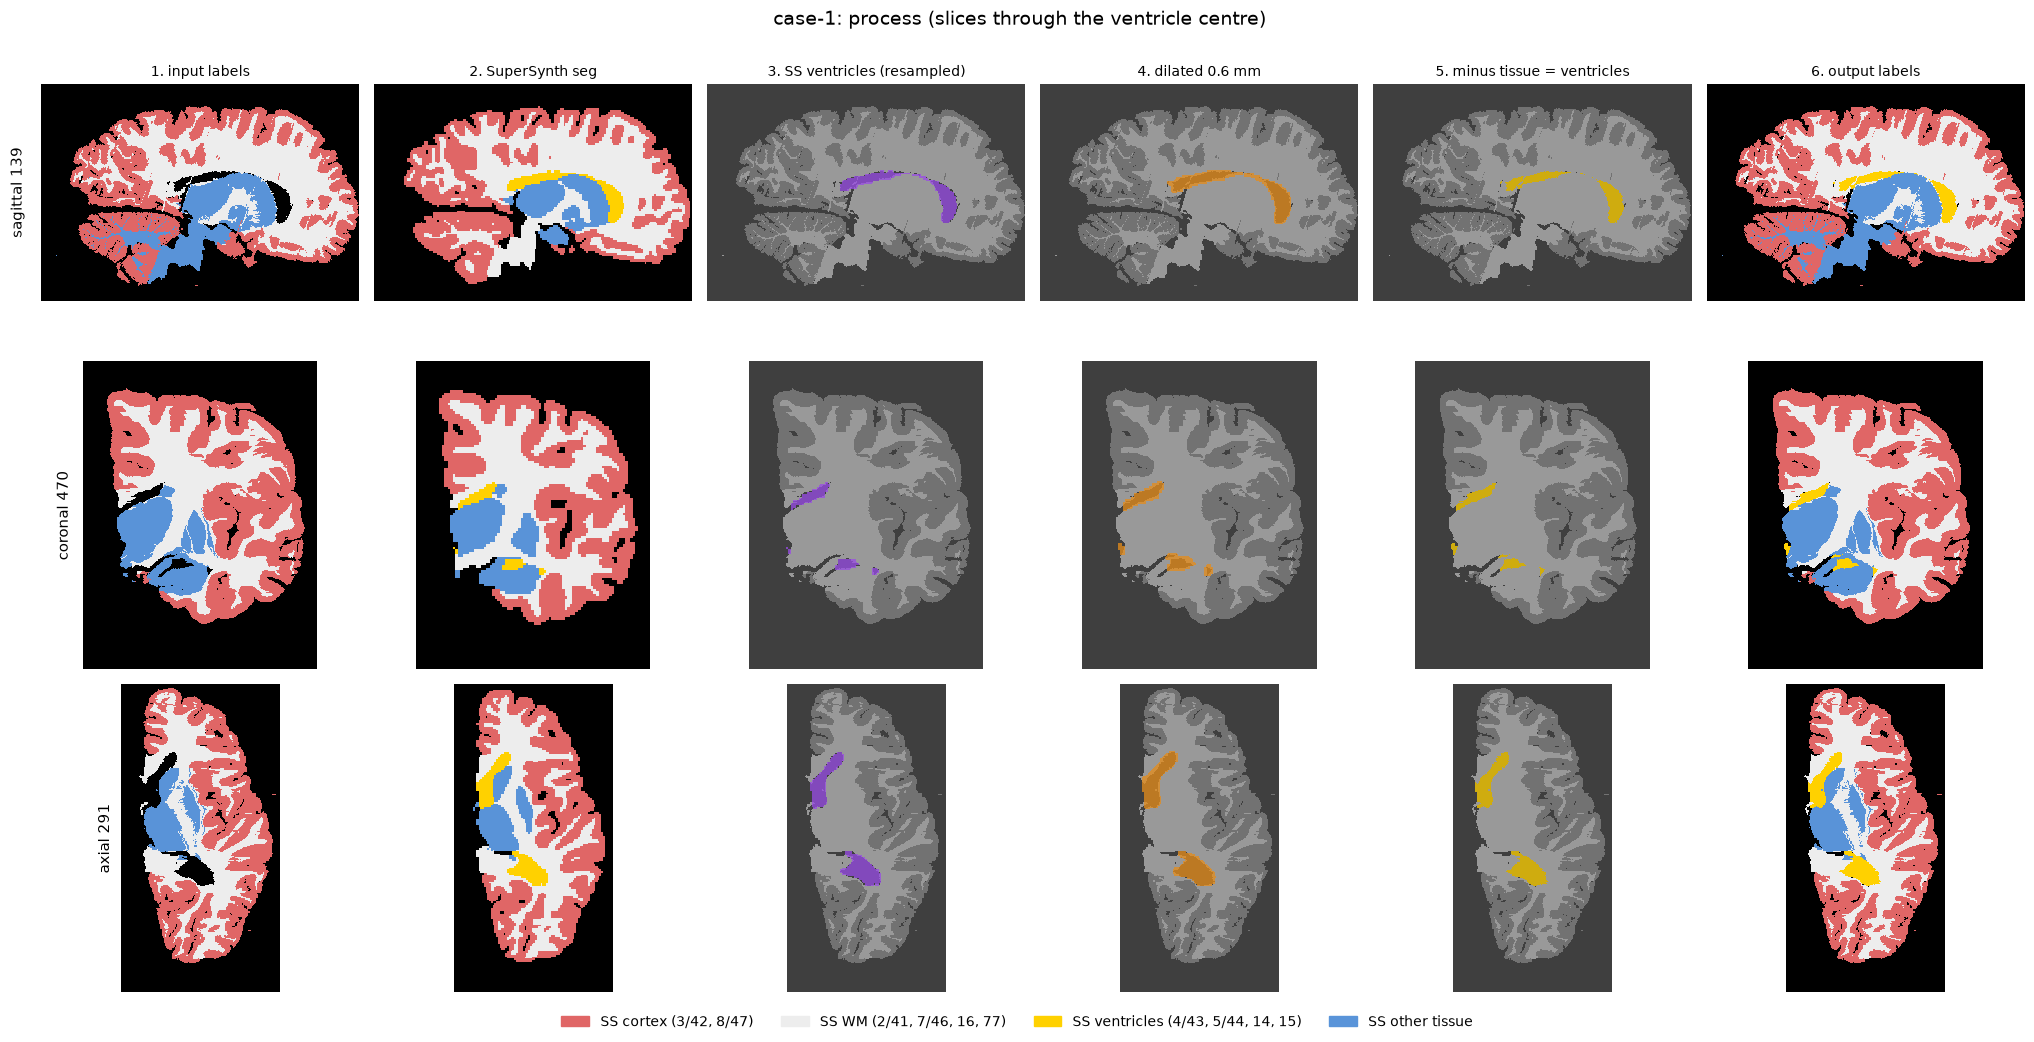

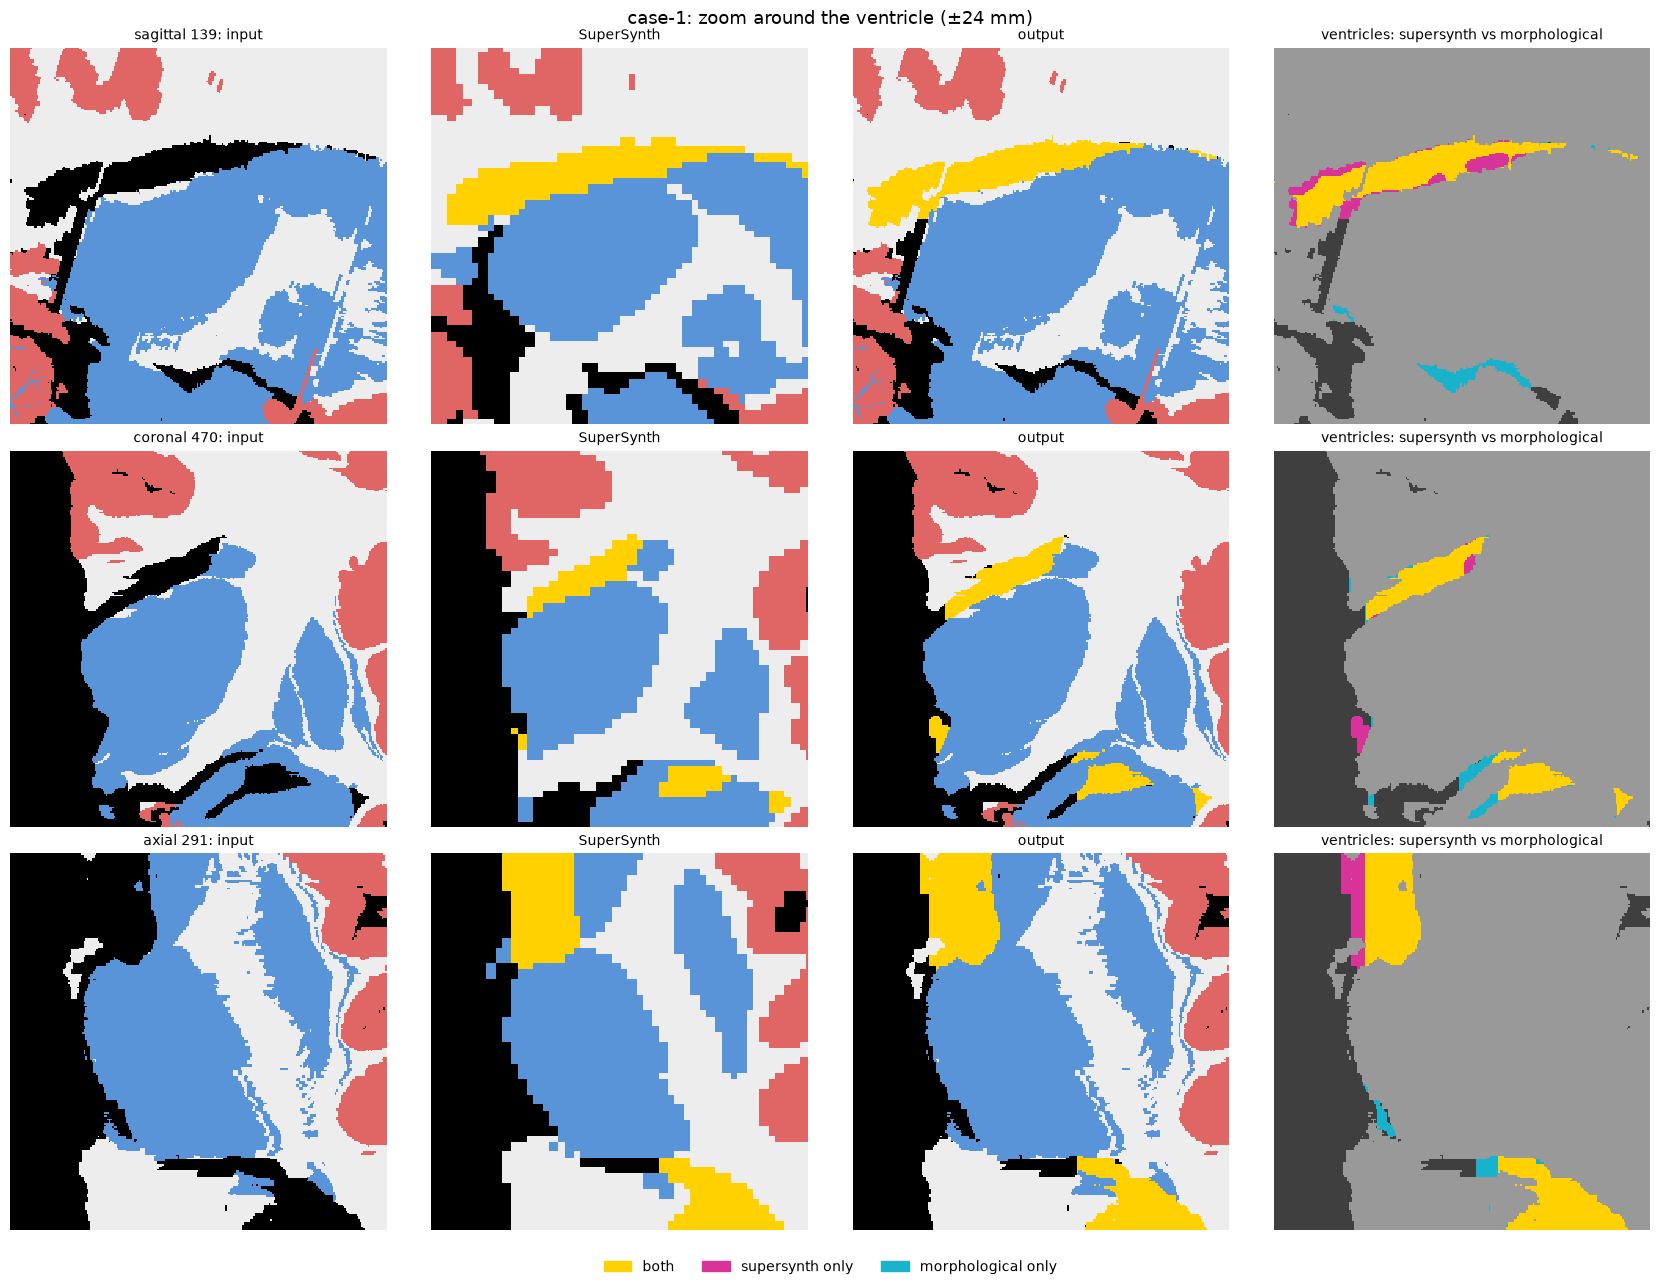

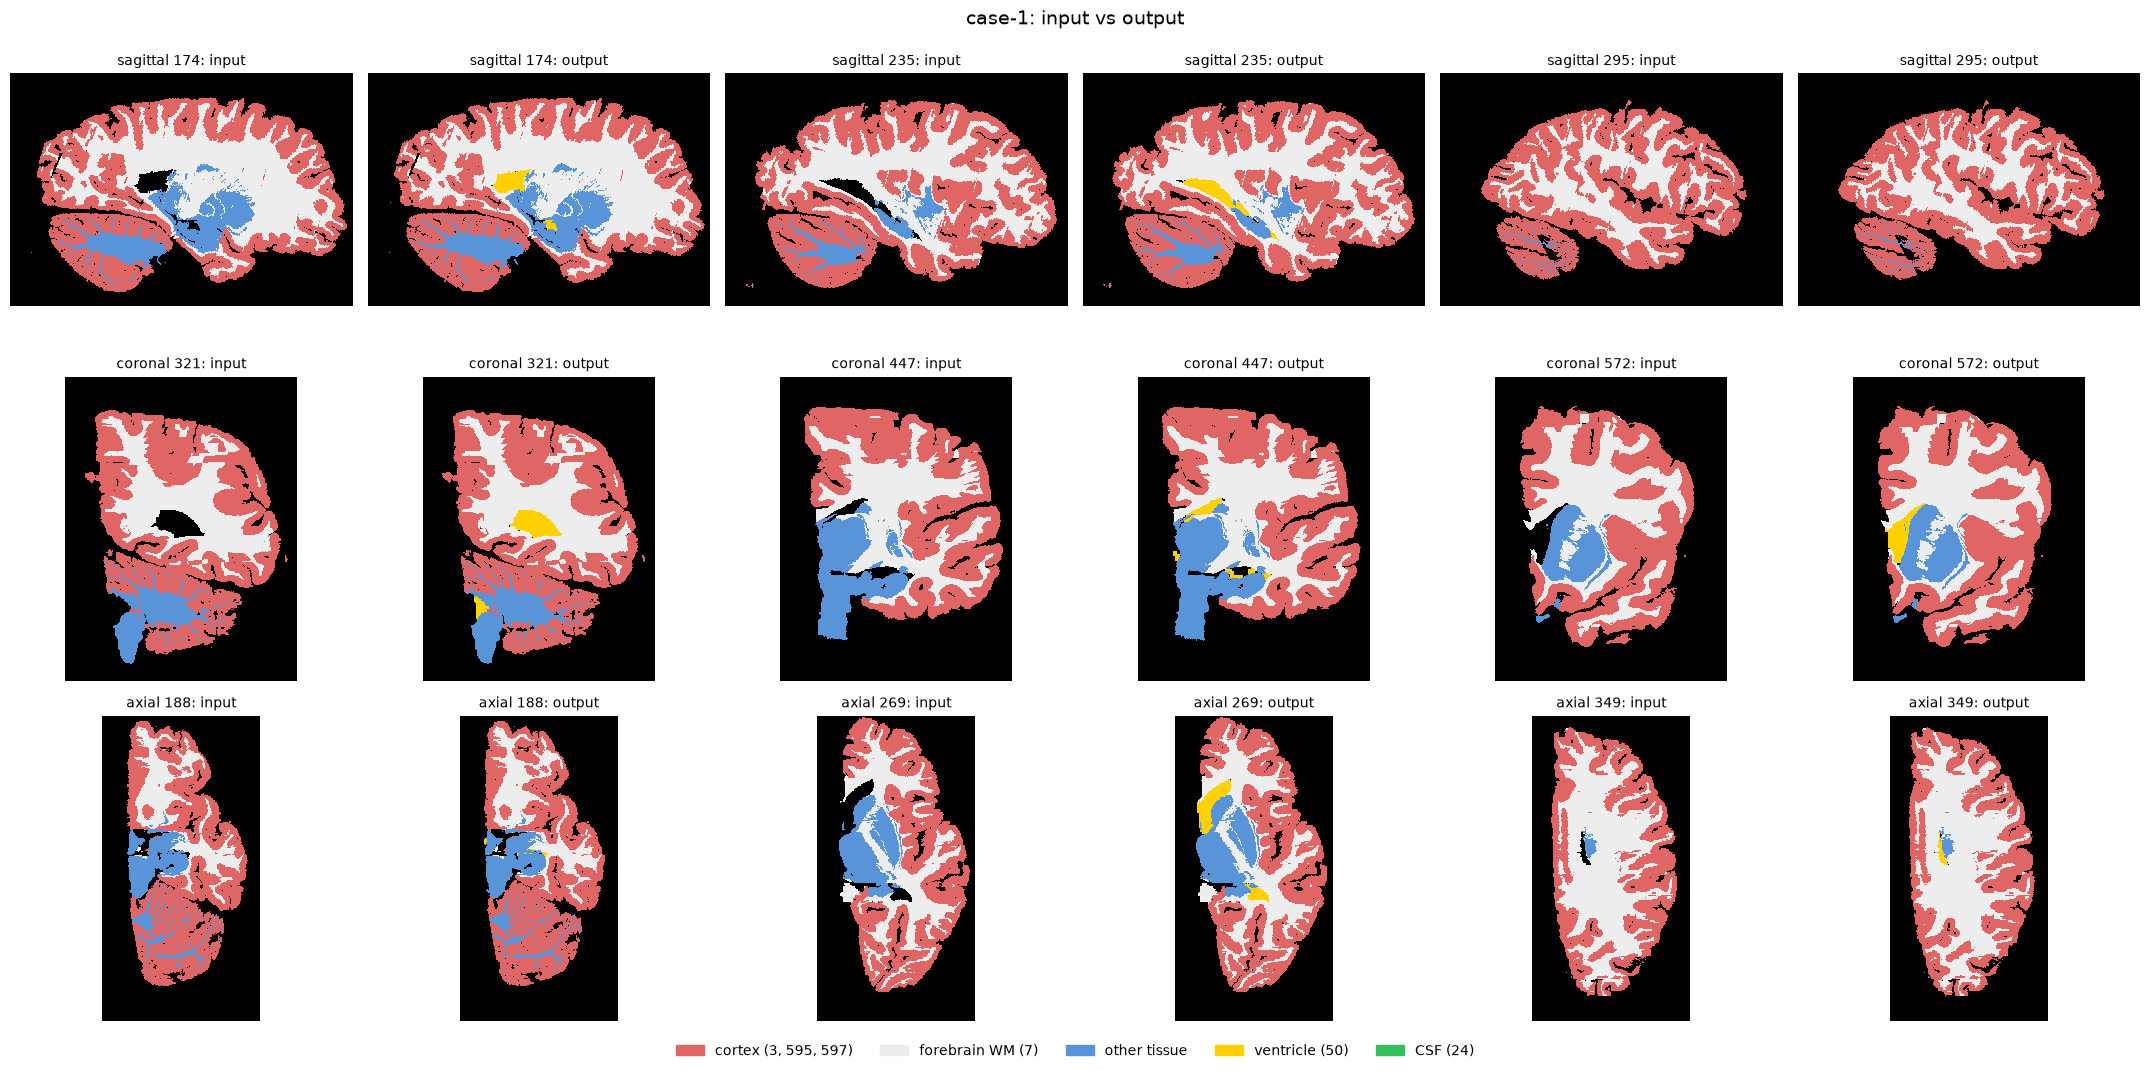

In [4]:
case = "case-1"
d = load_case(case)
ROWS = globals().setdefault("ROWS", {})
ROWS[case] = stats(case, d)
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in ROWS[case].items()})
plot_process(case, d)
plot_zoom(case, d)
plot_result(case, d)
del d

### case-2

{'case': 'case-2', 'supersynth ventricle (cm3)': np.float64(14.682), 'morphological ventricle (cm3)': np.float64(14.535), 'dice': np.float64(0.949), 'supersynth only (cm3)': np.float64(0.812), 'morphological only (cm3)': np.float64(0.666)}


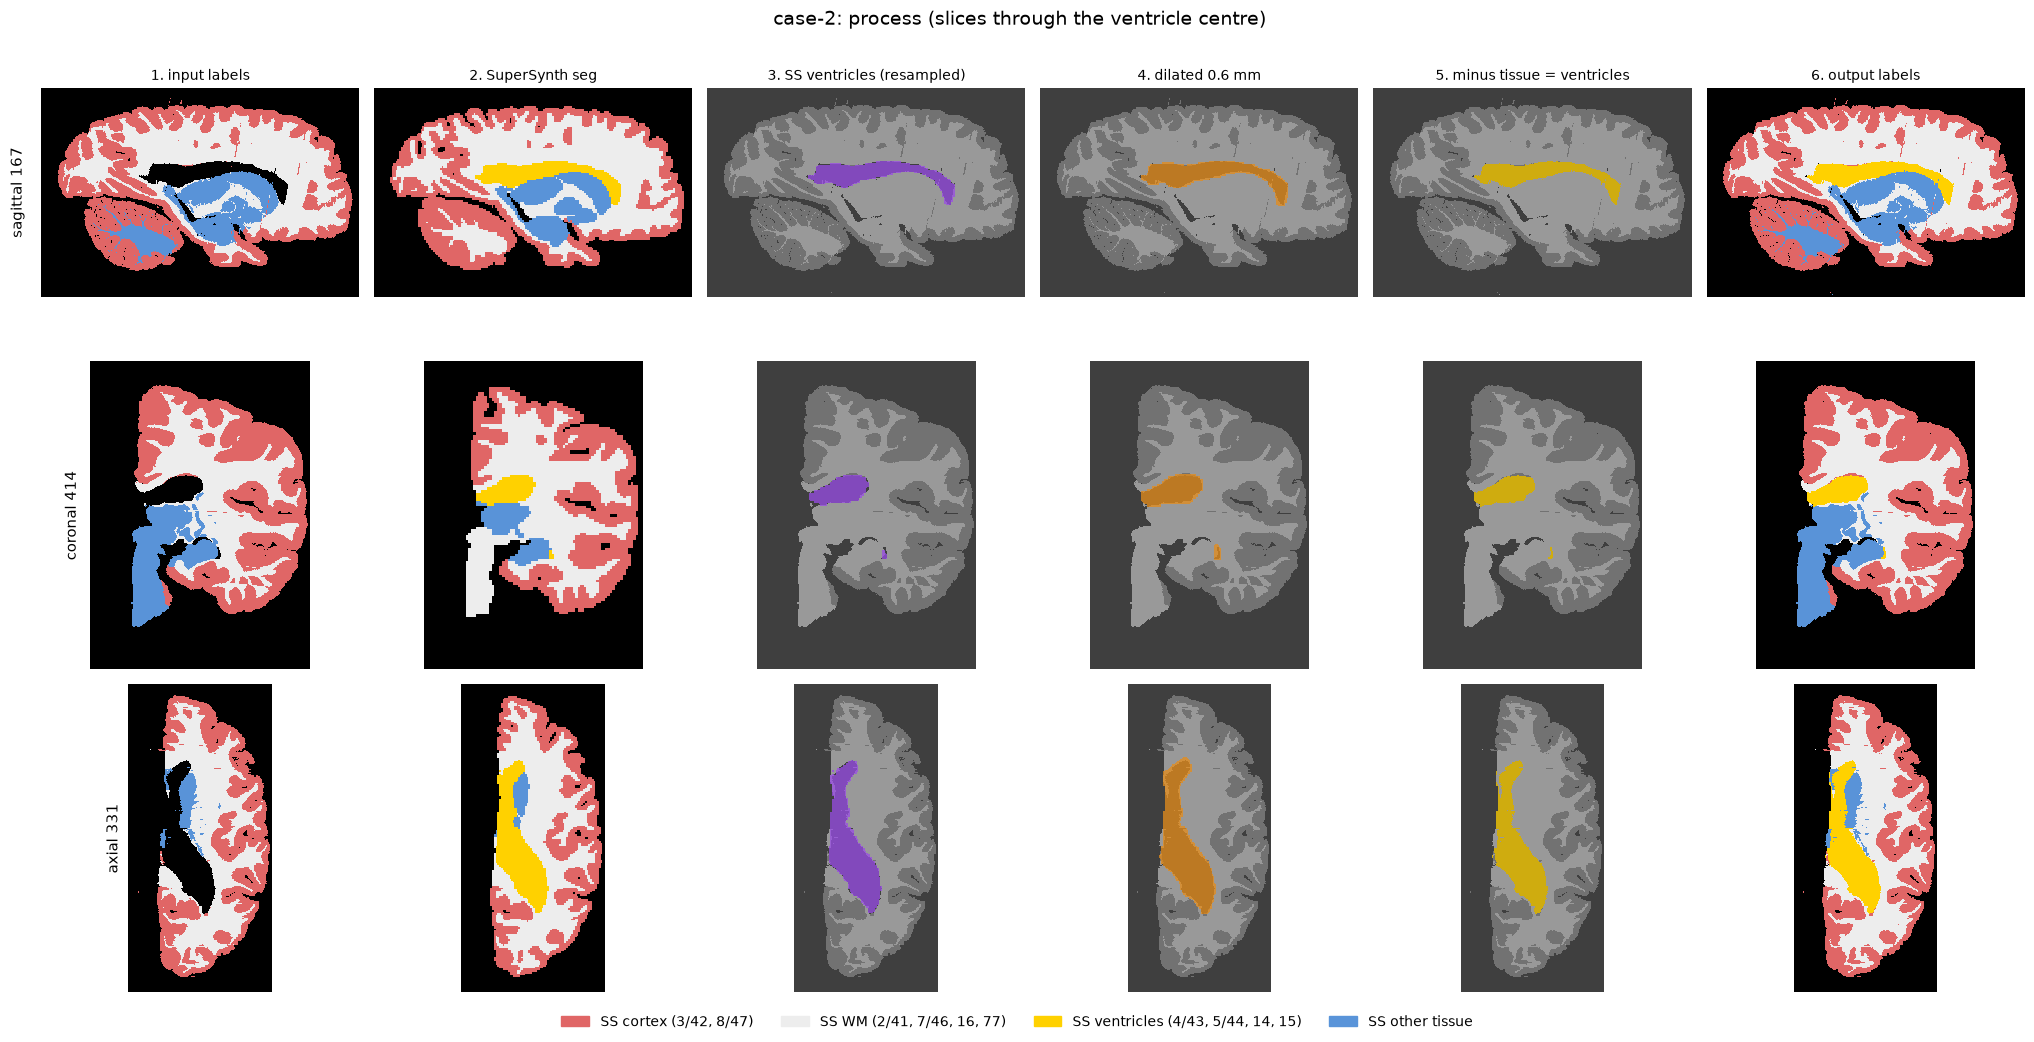

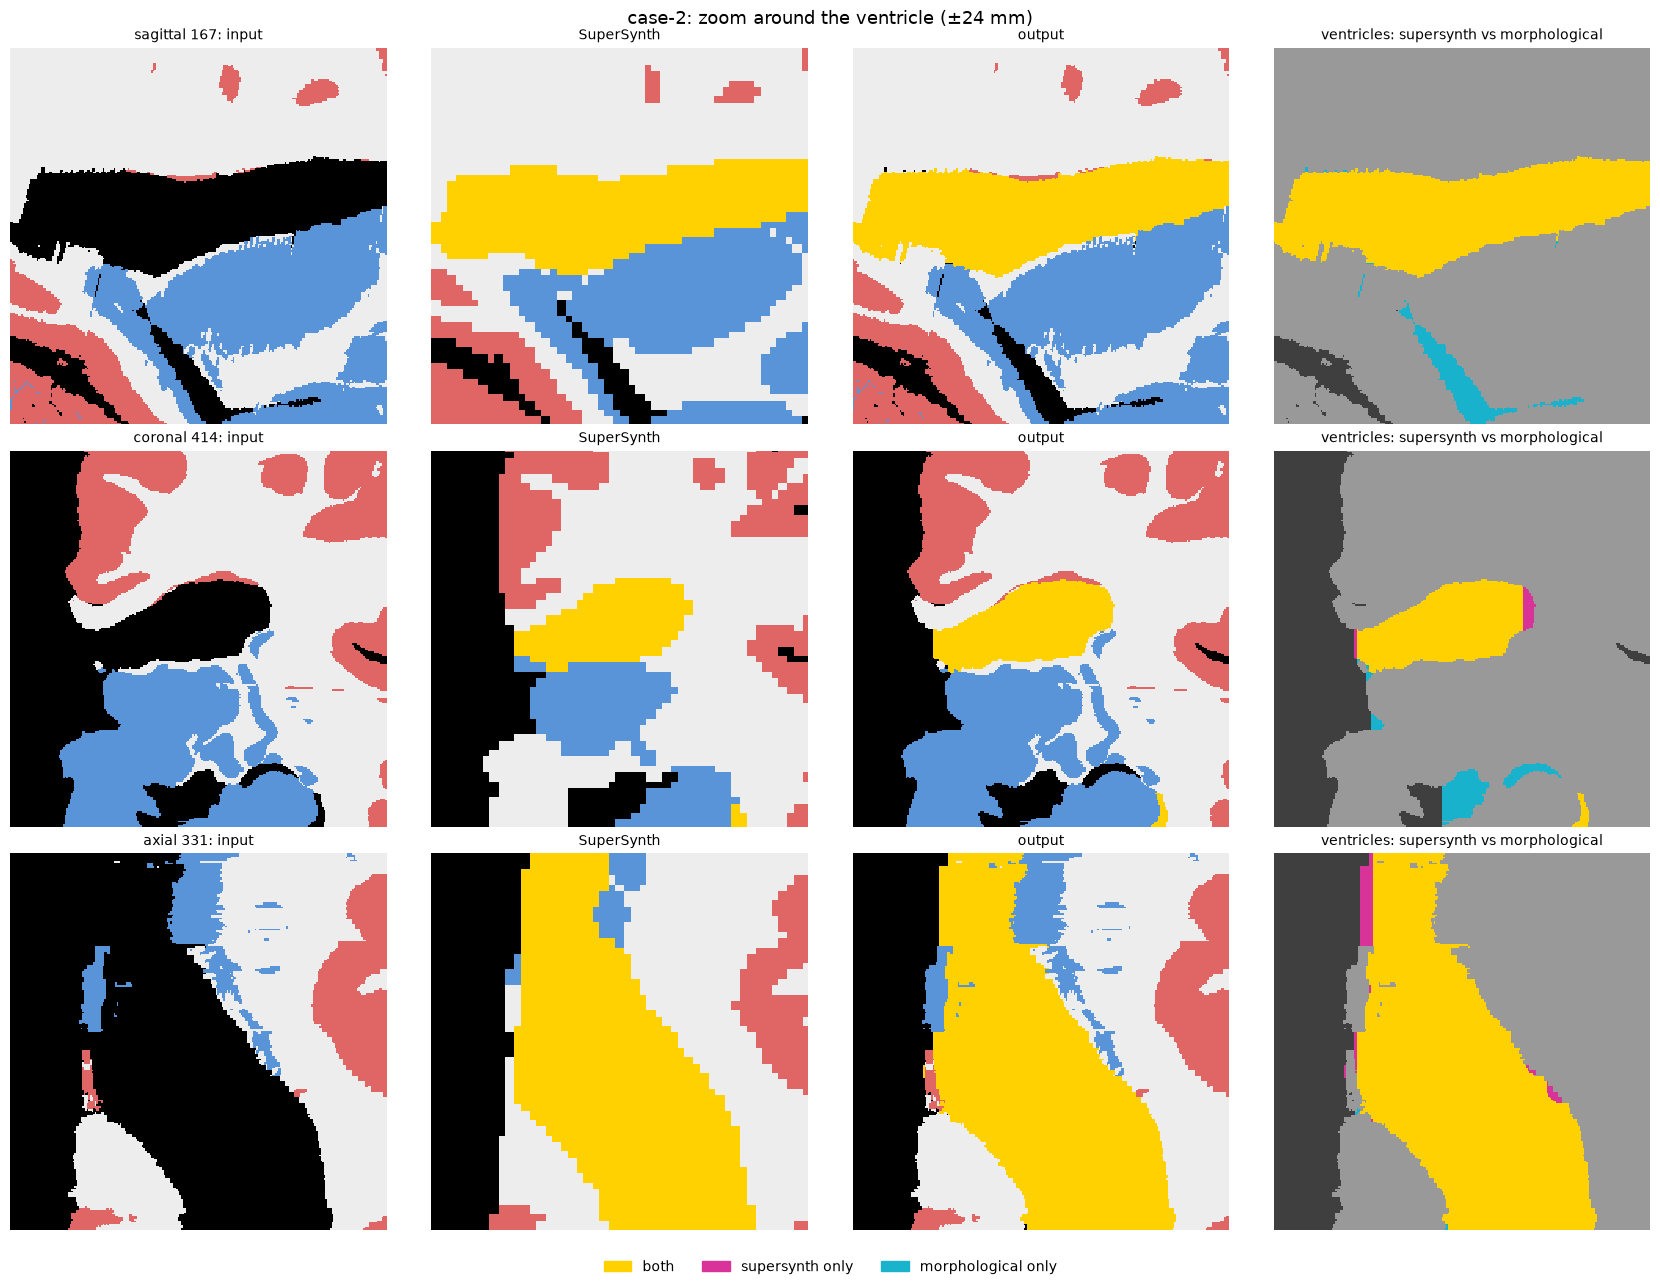

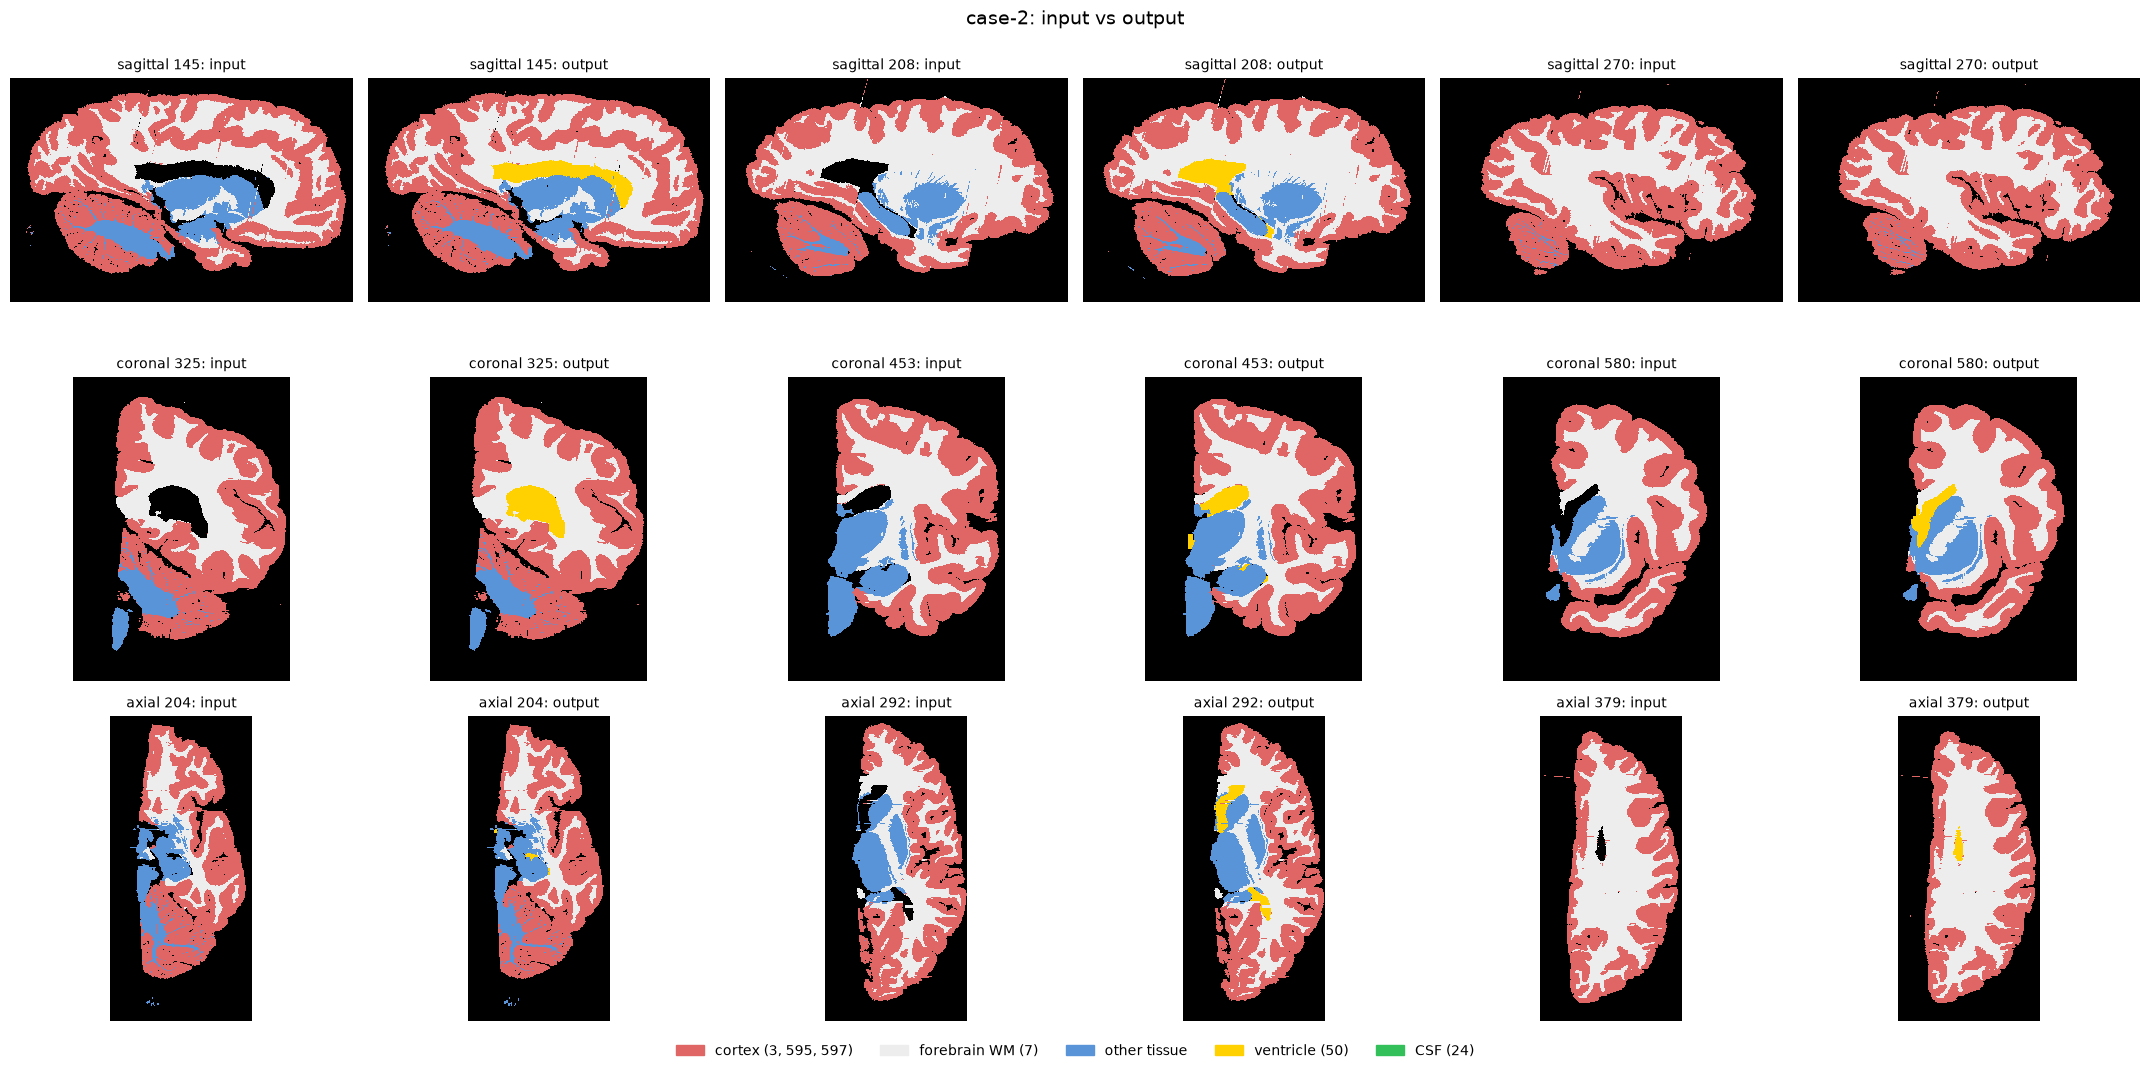

In [5]:
case = "case-2"
d = load_case(case)
ROWS = globals().setdefault("ROWS", {})
ROWS[case] = stats(case, d)
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in ROWS[case].items()})
plot_process(case, d)
plot_zoom(case, d)
plot_result(case, d)
del d

### case-3

{'case': 'case-3', 'supersynth ventricle (cm3)': np.float64(16.121), 'morphological ventricle (cm3)': np.float64(14.672), 'dice': np.float64(0.891), 'supersynth only (cm3)': np.float64(2.407), 'morphological only (cm3)': np.float64(0.957)}


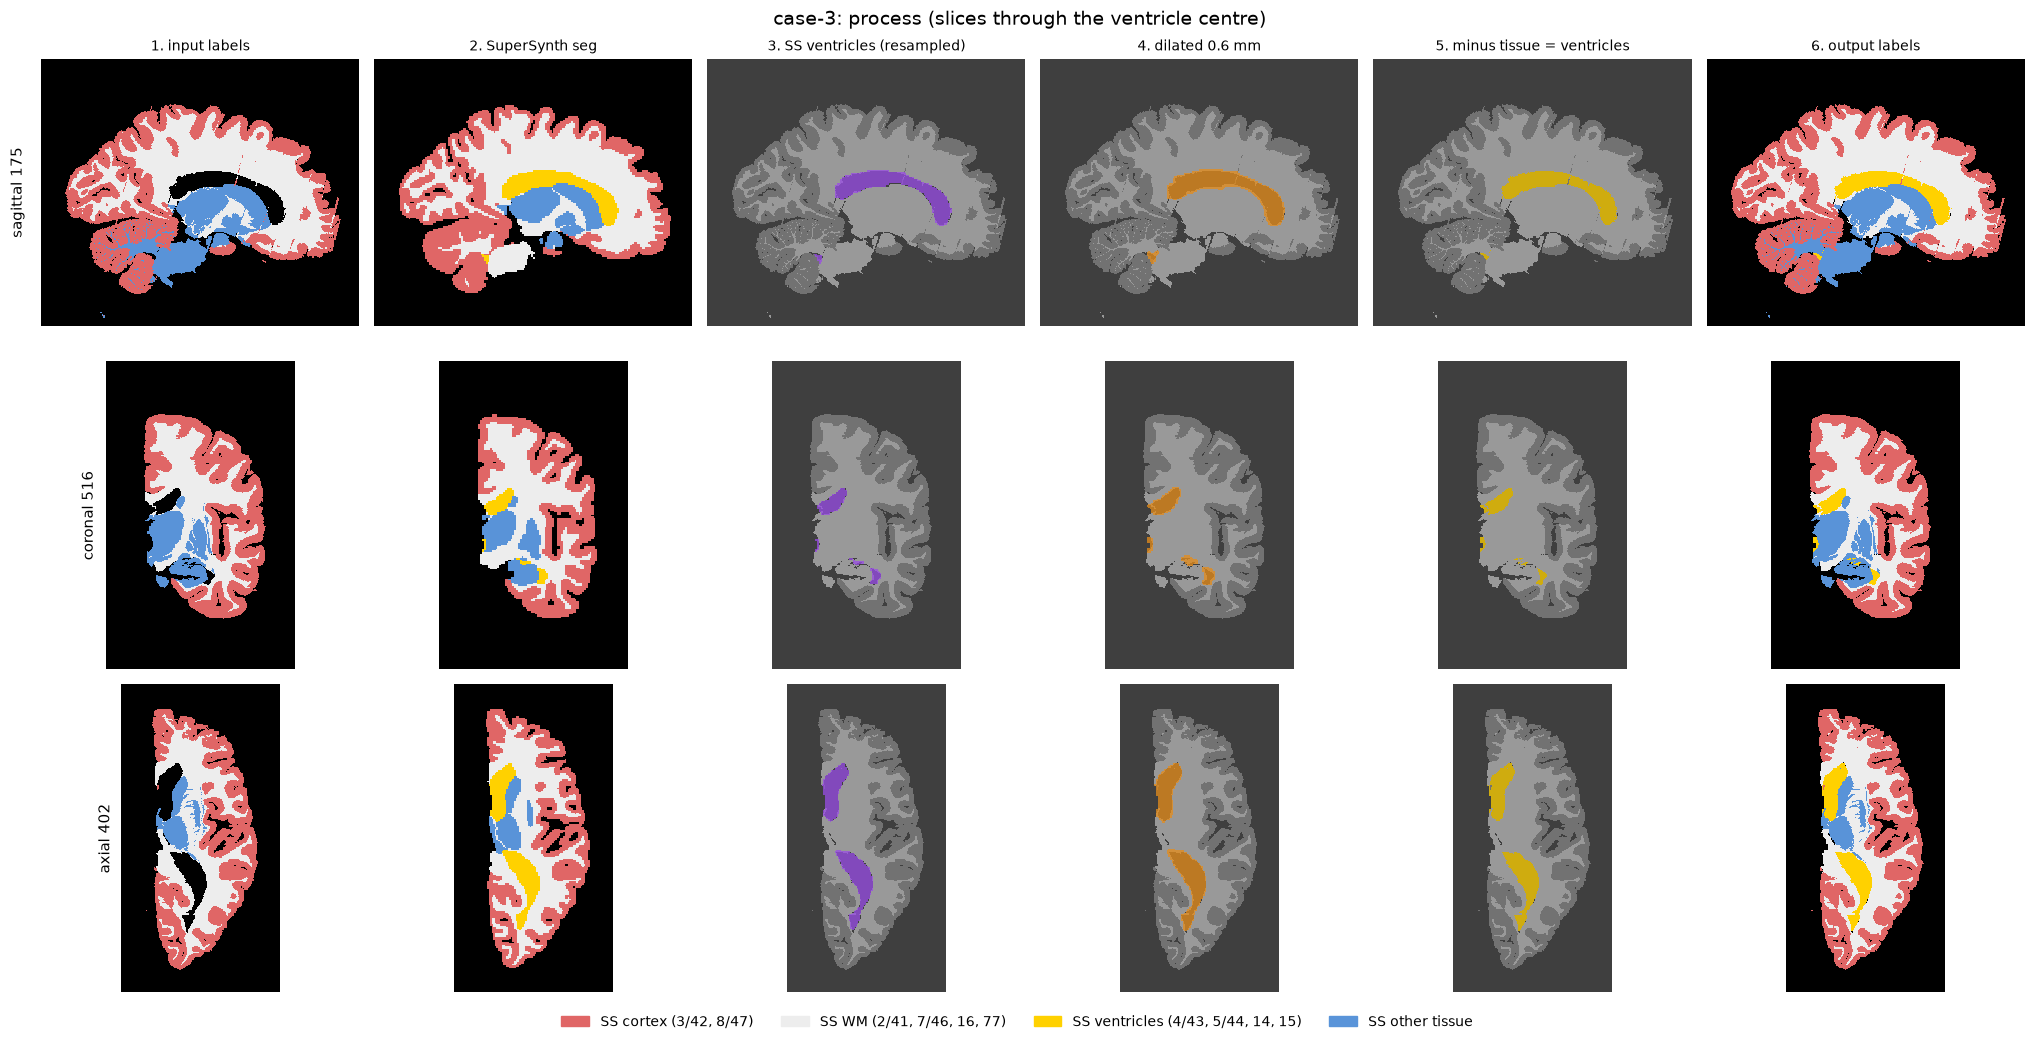

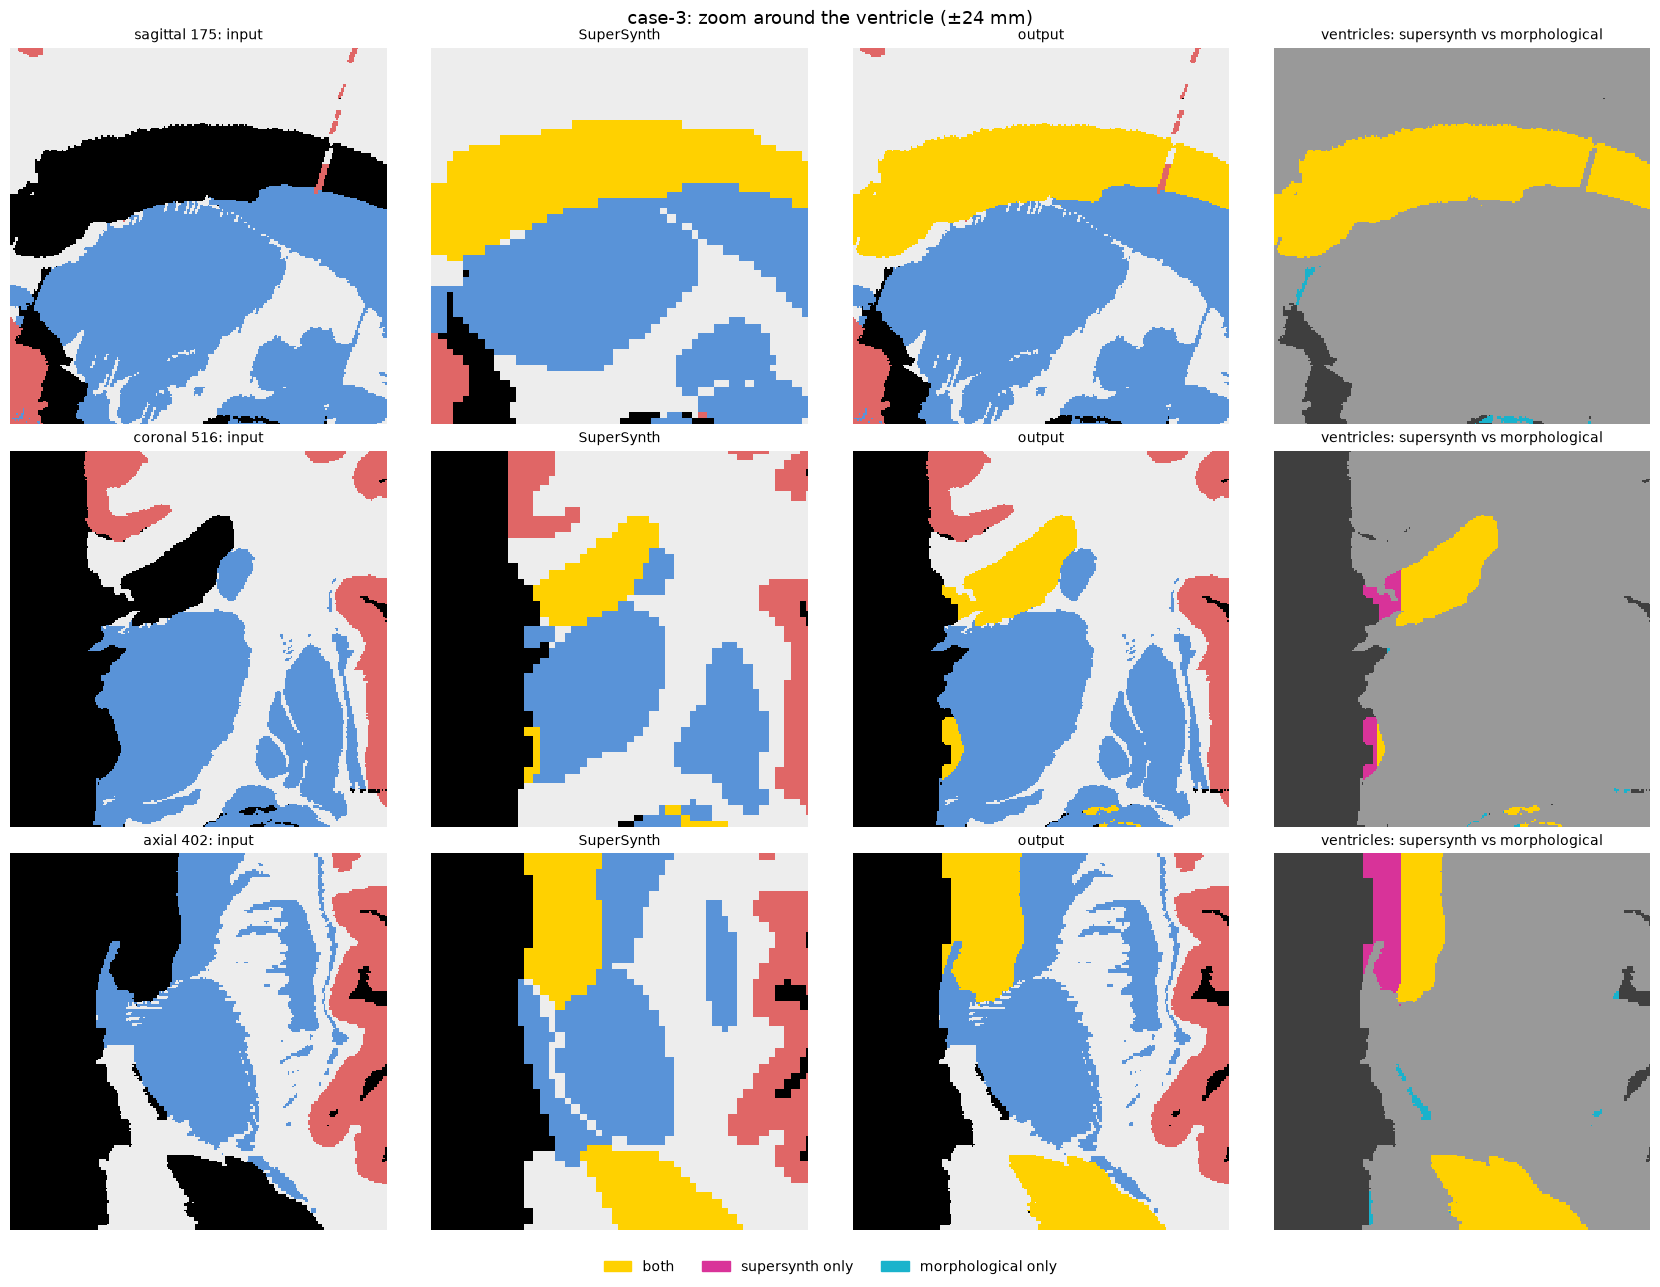

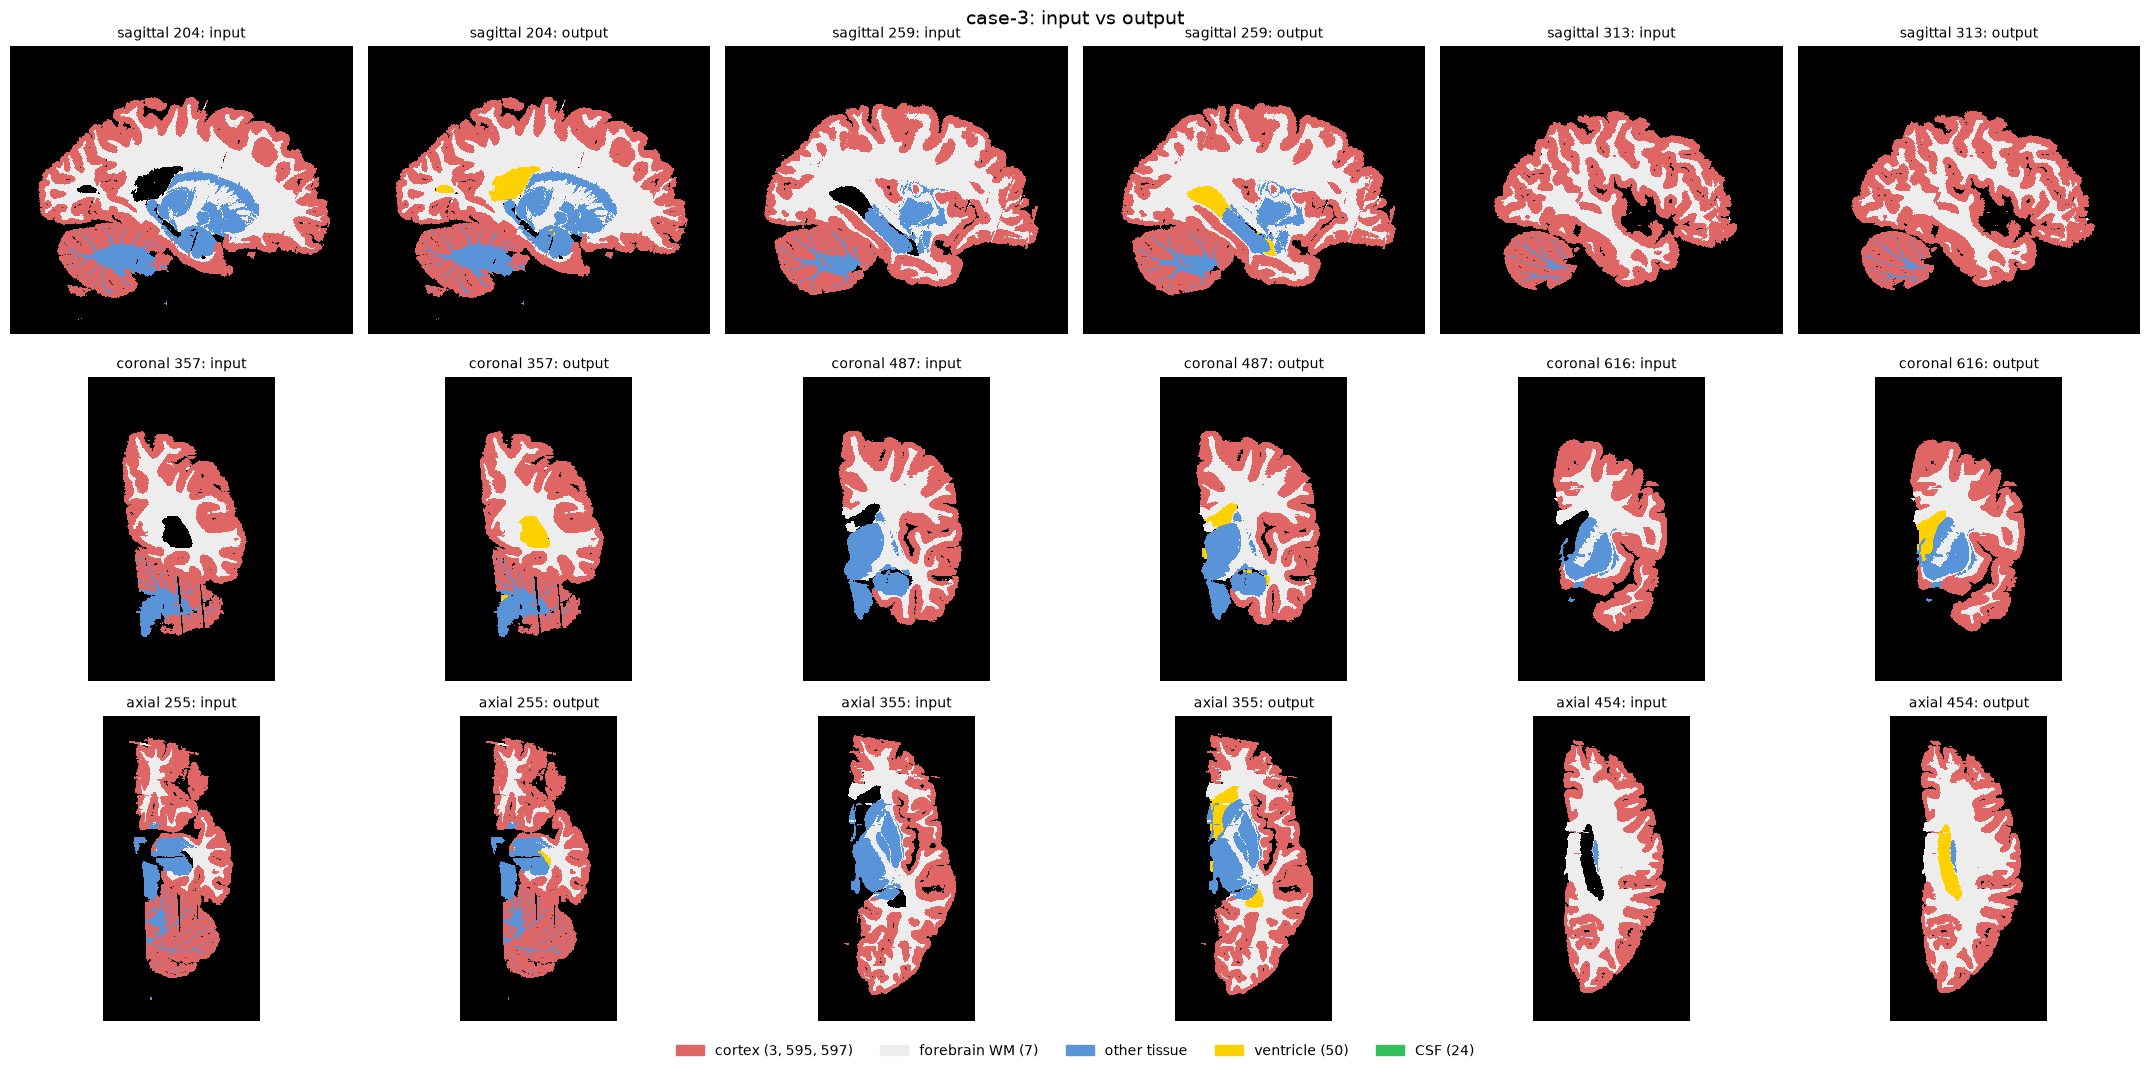

In [6]:
case = "case-3"
d = load_case(case)
ROWS = globals().setdefault("ROWS", {})
ROWS[case] = stats(case, d)
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in ROWS[case].items()})
plot_process(case, d)
plot_zoom(case, d)
plot_result(case, d)
del d

### case-4

{'case': 'case-4', 'supersynth ventricle (cm3)': np.float64(14.874), 'morphological ventricle (cm3)': np.float64(10.887), 'dice': np.float64(0.748), 'supersynth only (cm3)': np.float64(5.245), 'morphological only (cm3)': np.float64(1.259)}


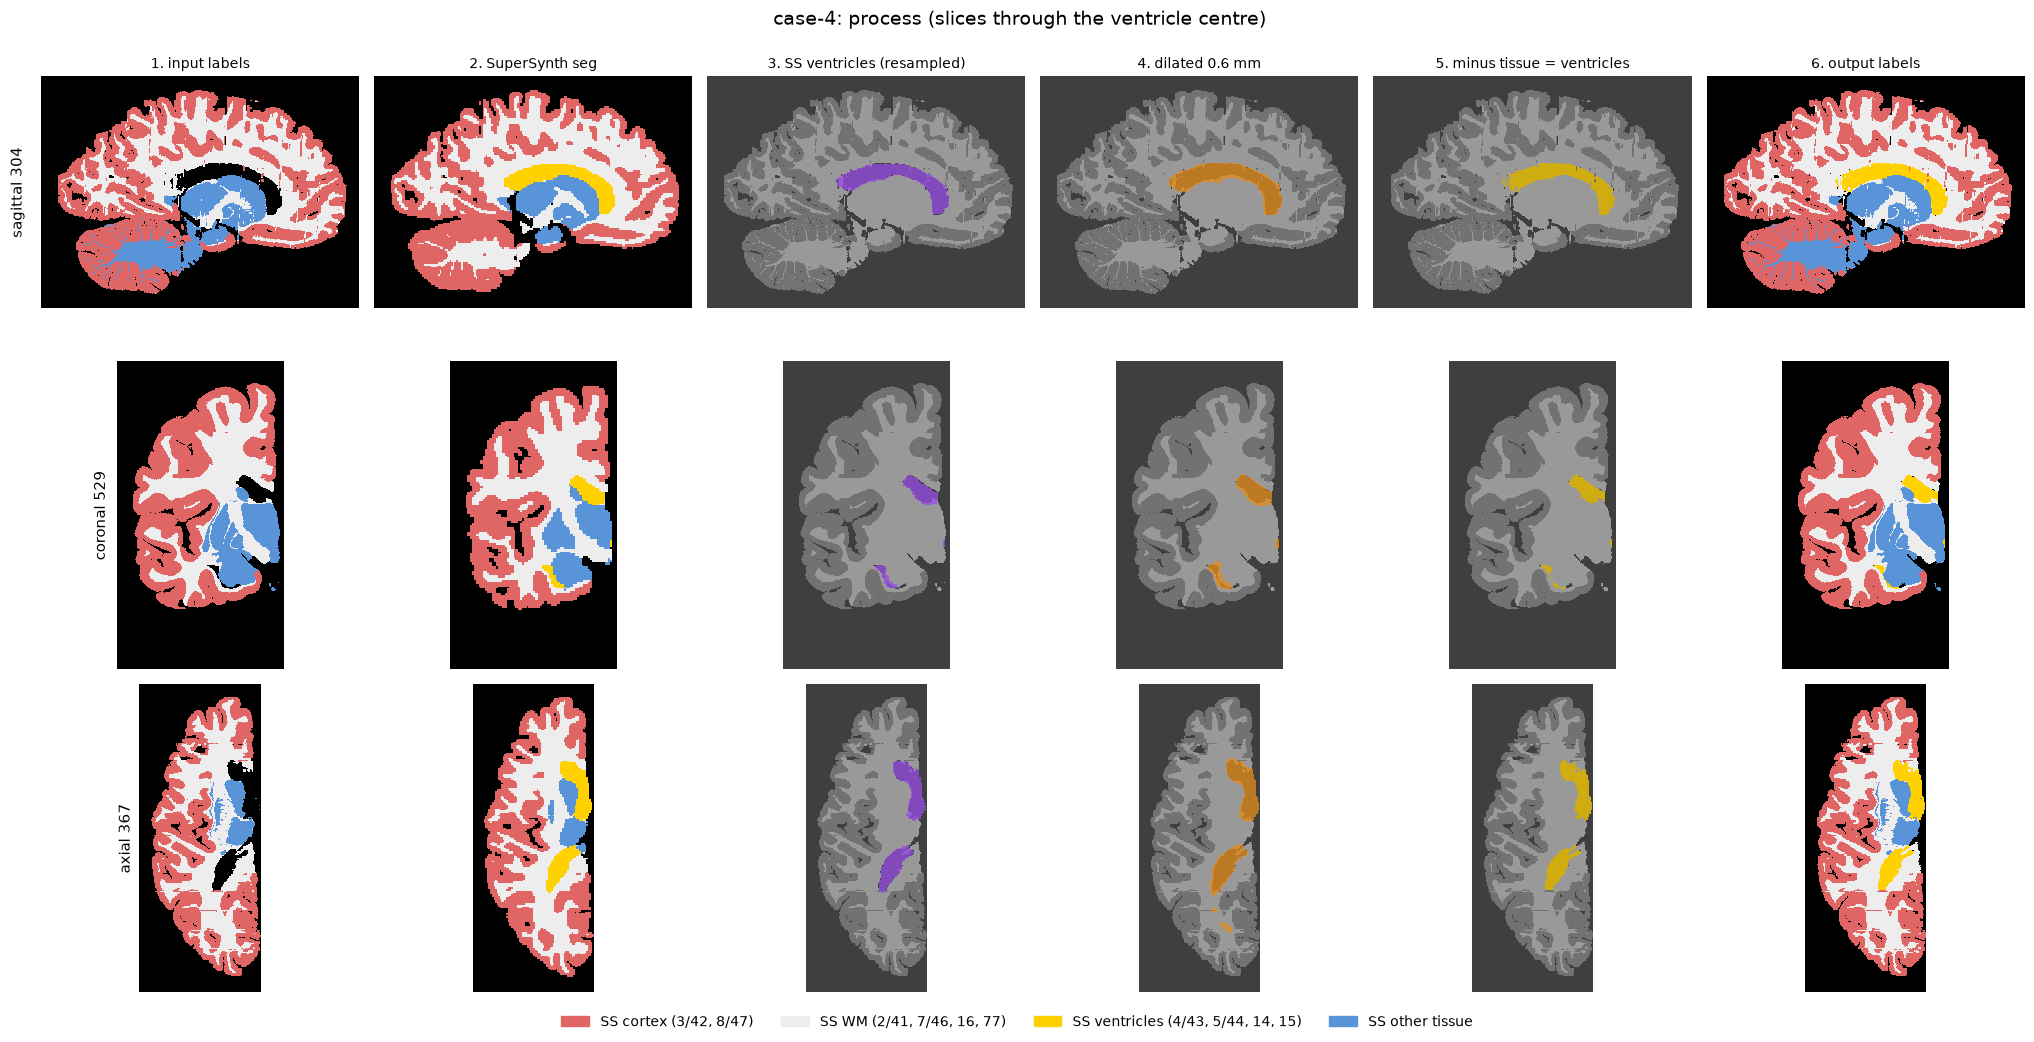

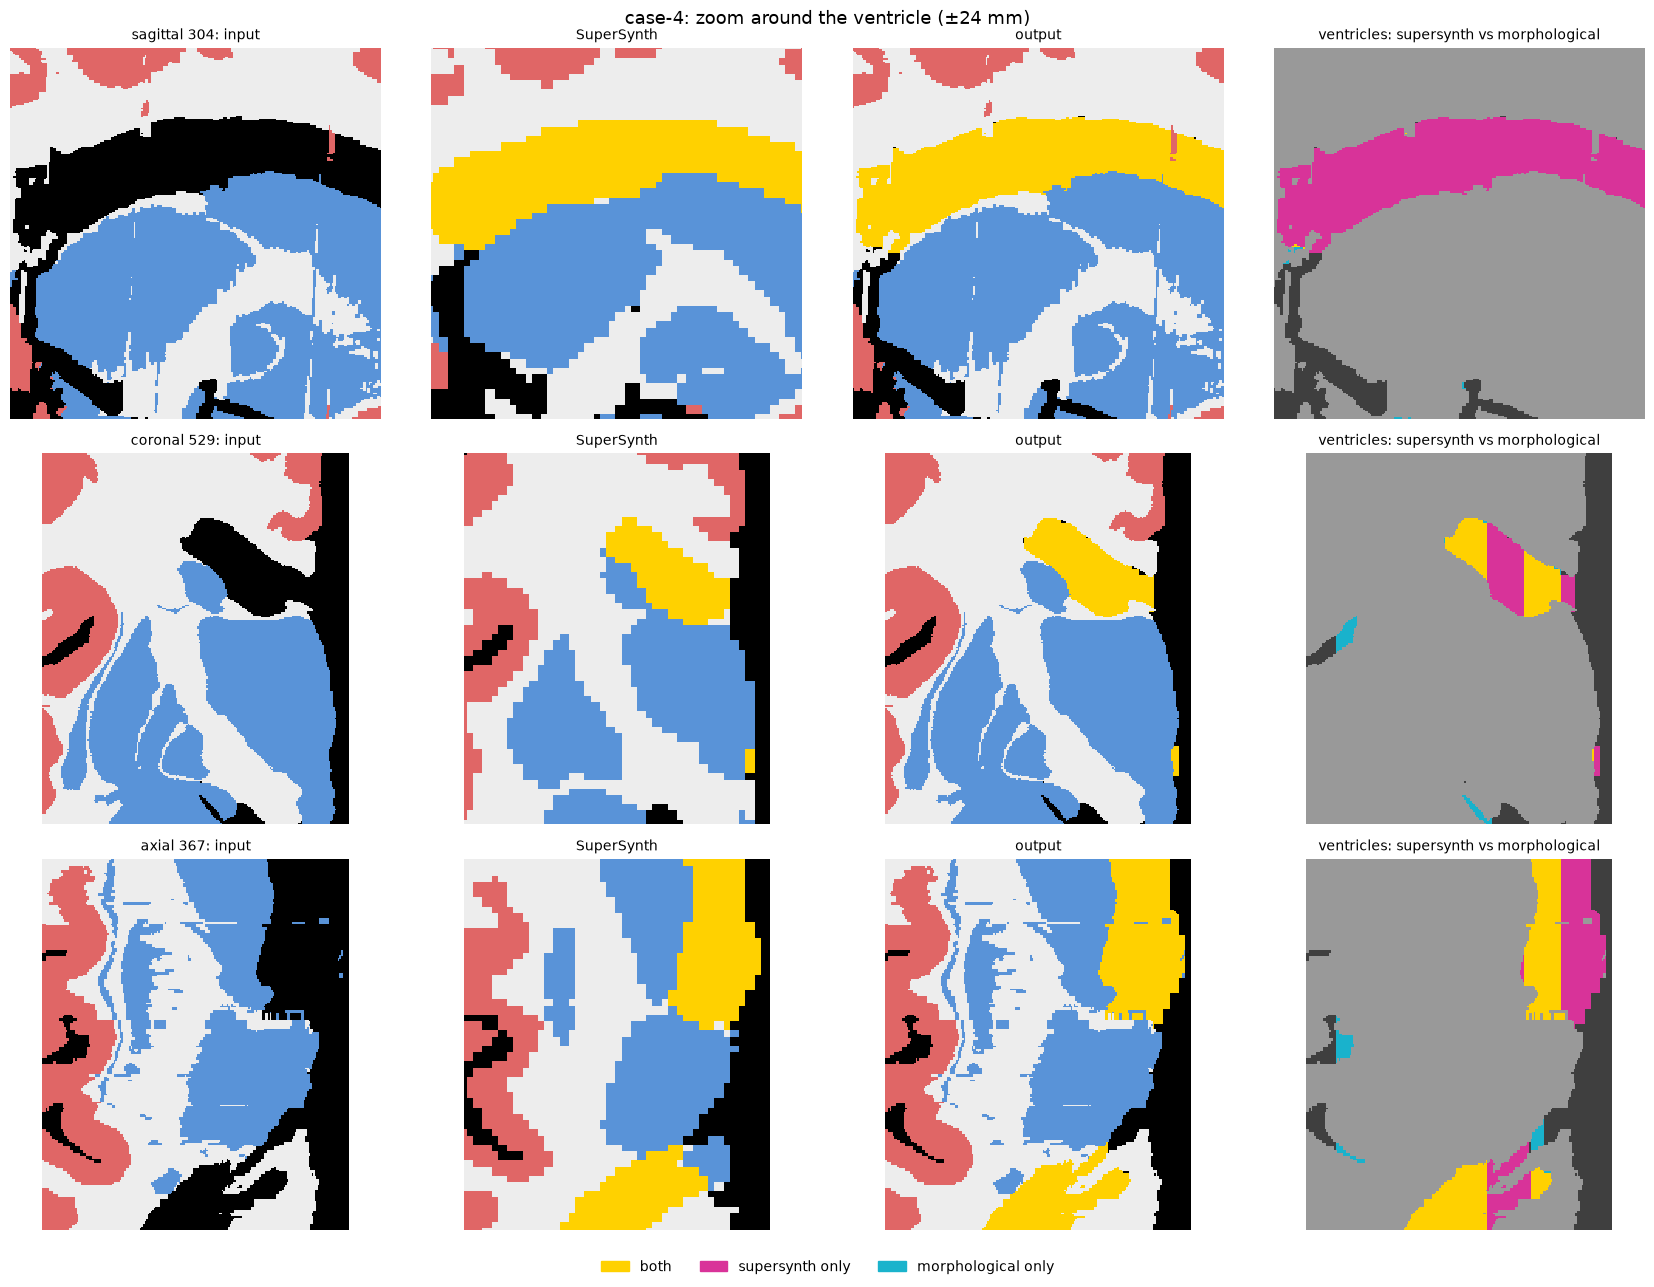

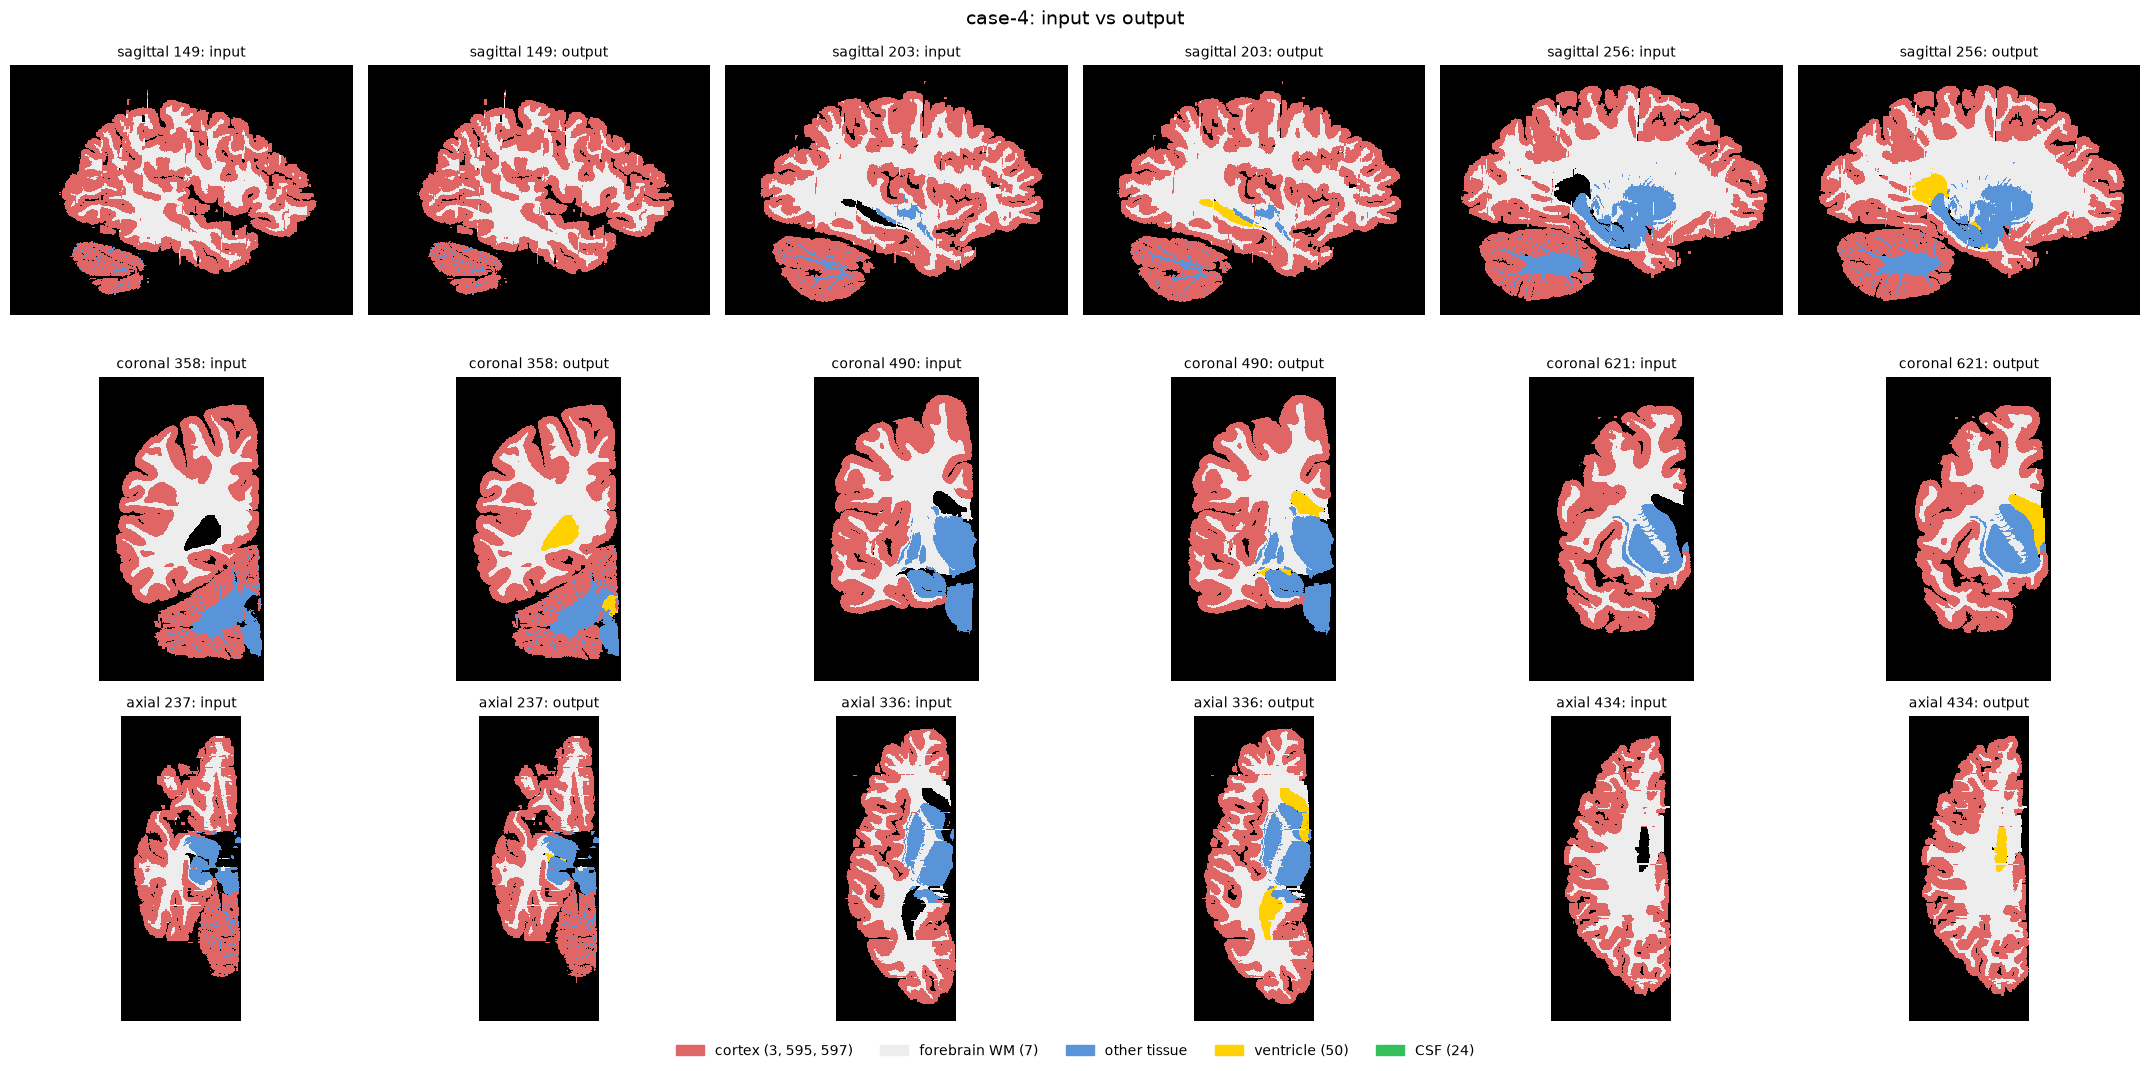

In [7]:
case = "case-4"
d = load_case(case)
ROWS = globals().setdefault("ROWS", {})
ROWS[case] = stats(case, d)
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in ROWS[case].items()})
plot_process(case, d)
plot_zoom(case, d)
plot_result(case, d)
del d

### case-5

{'case': 'case-5', 'supersynth ventricle (cm3)': np.float64(11.865), 'morphological ventricle (cm3)': np.float64(11.498), 'dice': np.float64(0.861), 'supersynth only (cm3)': np.float64(1.804), 'morphological only (cm3)': np.float64(1.436)}


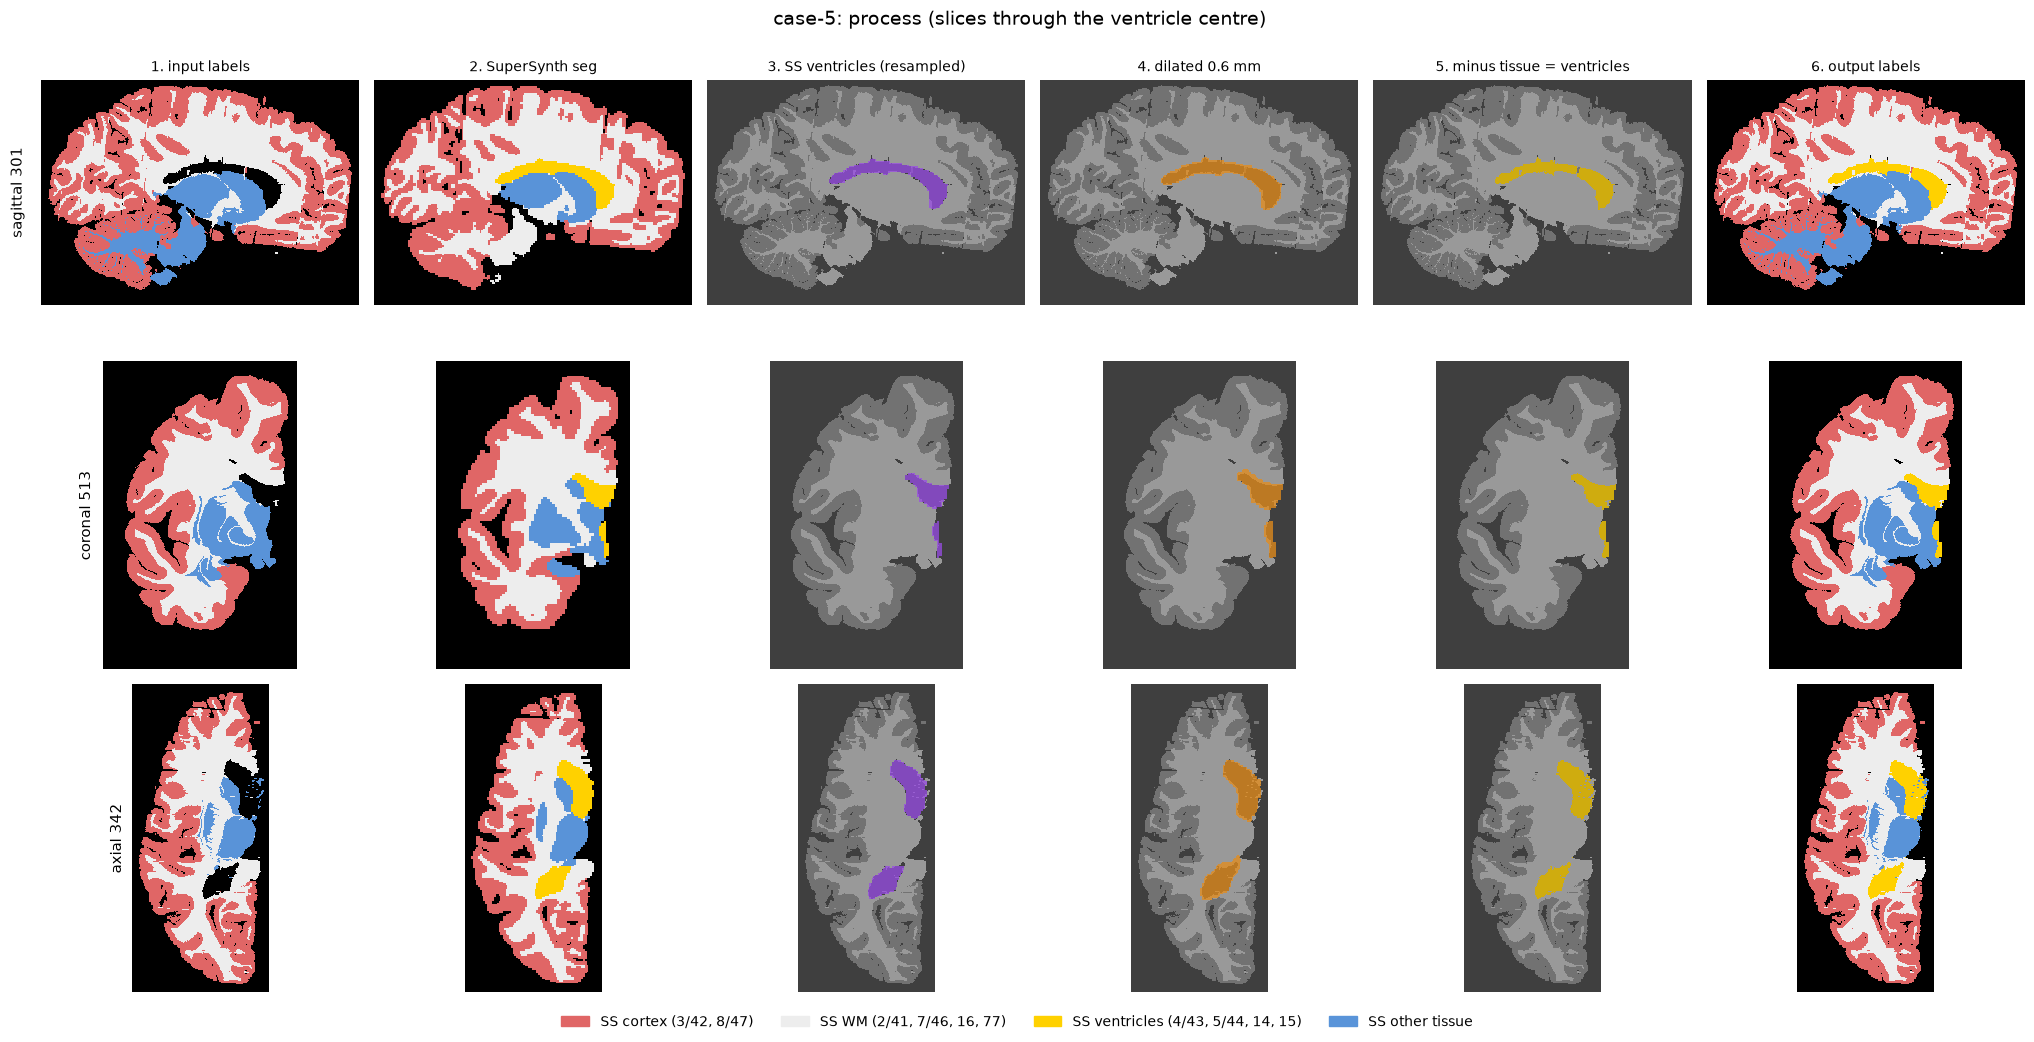

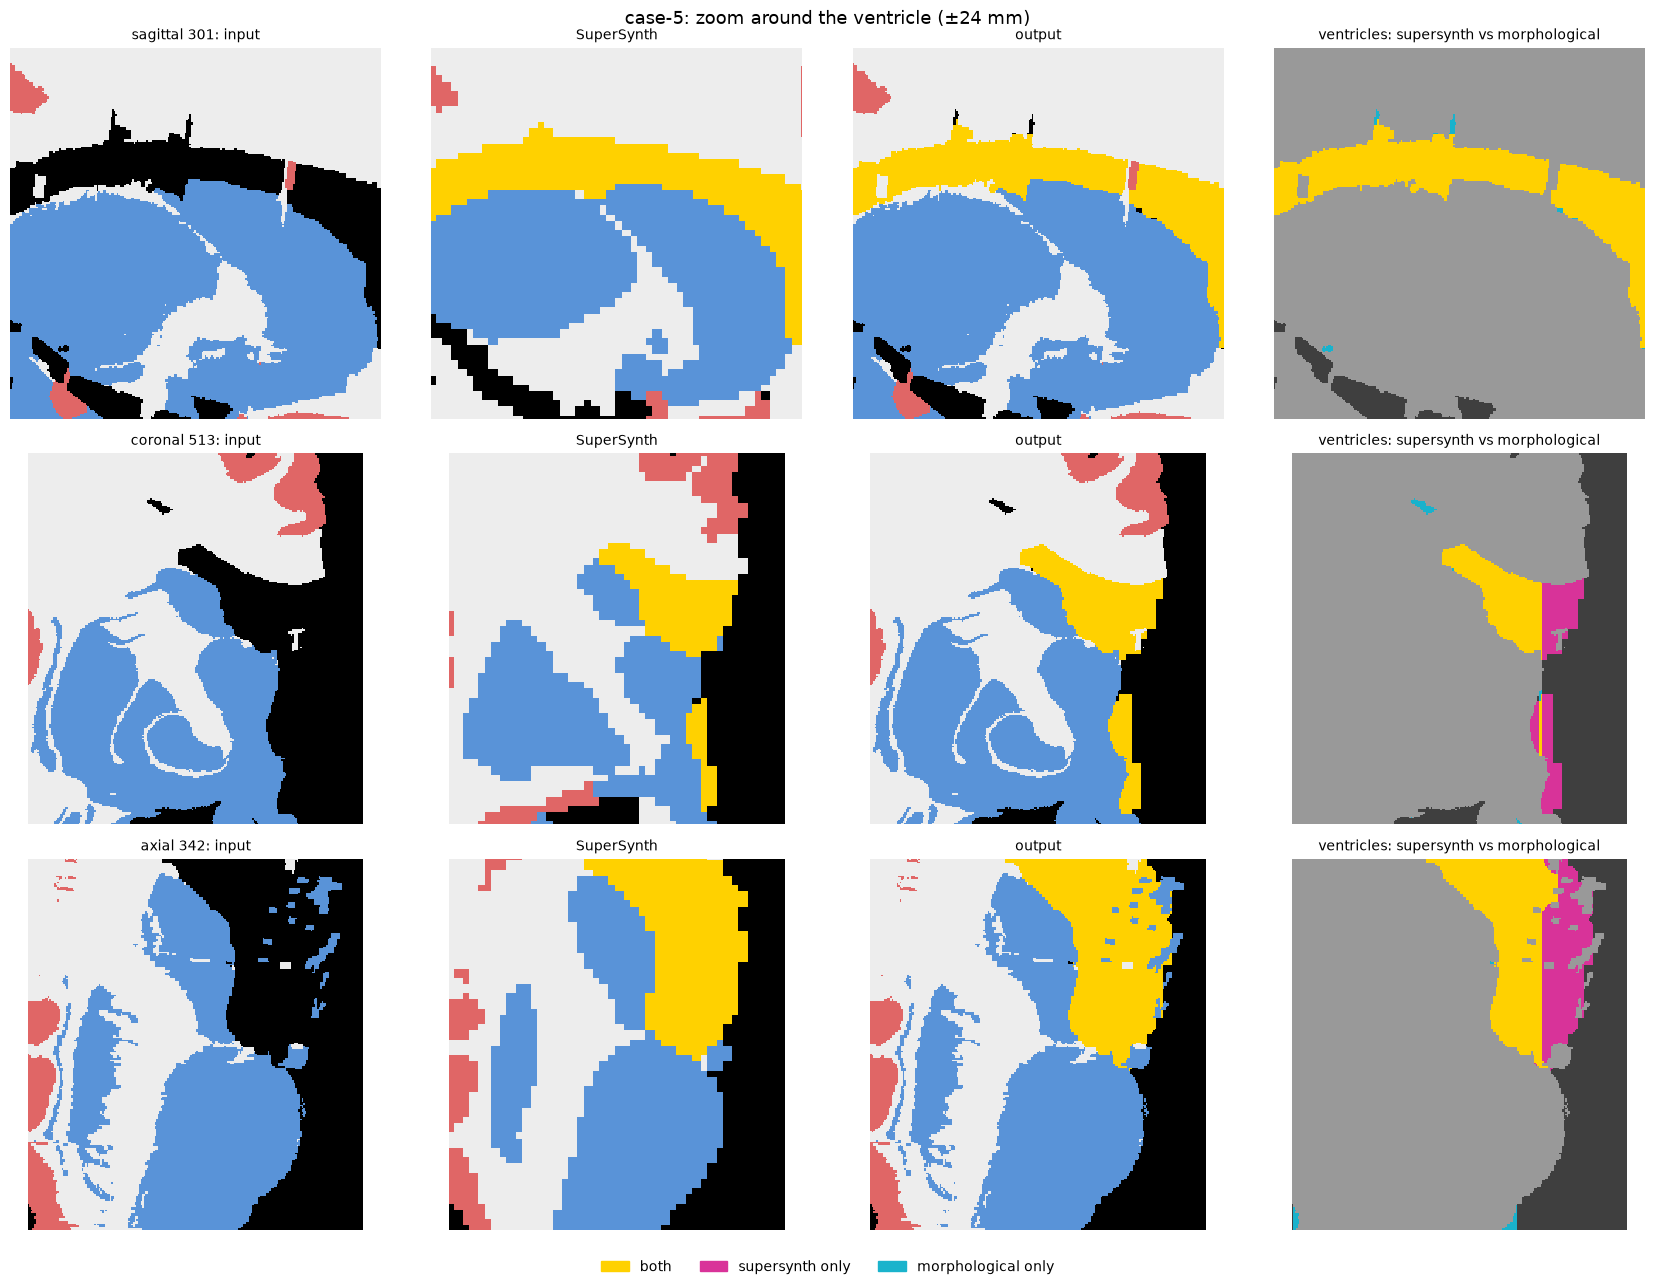

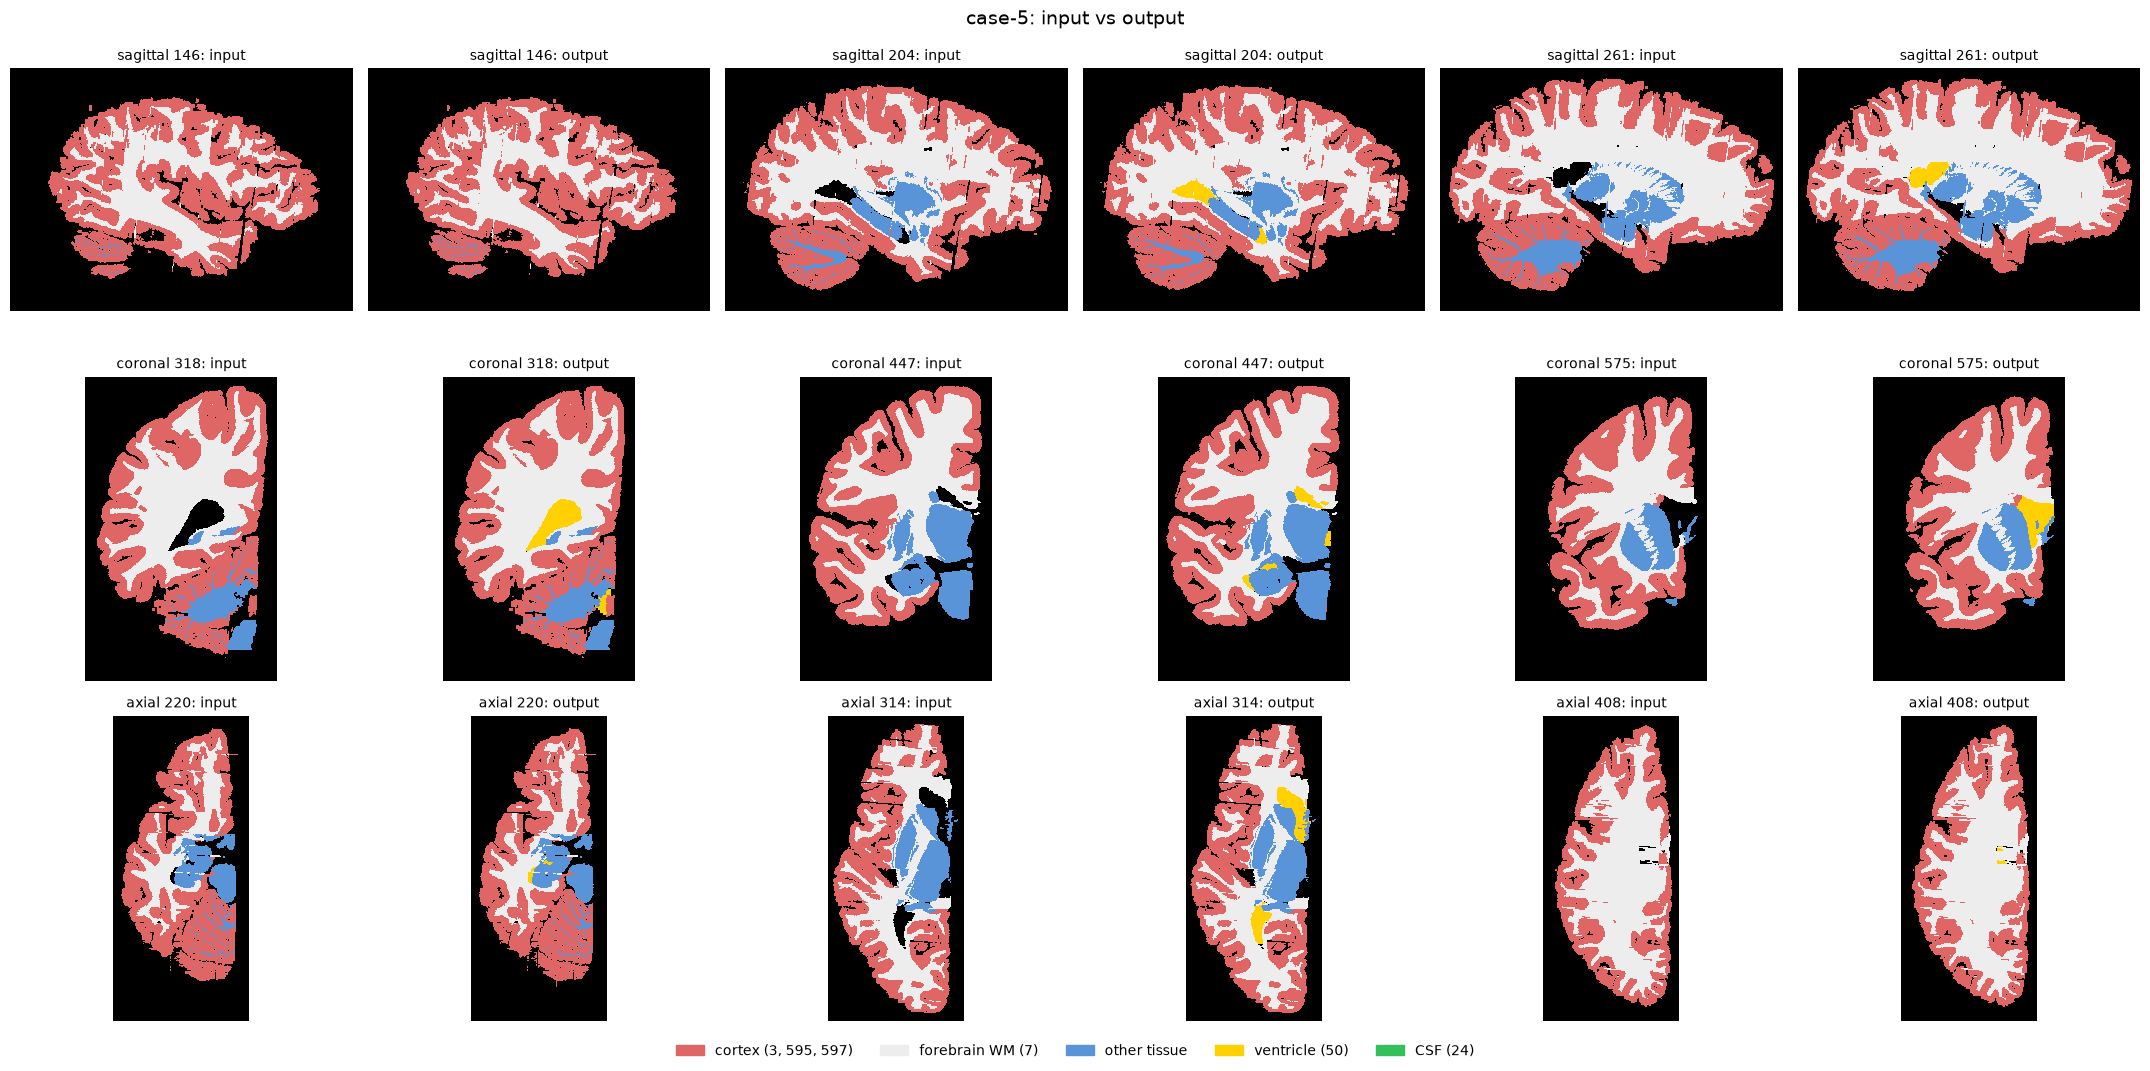

In [8]:
case = "case-5"
d = load_case(case)
ROWS = globals().setdefault("ROWS", {})
ROWS[case] = stats(case, d)
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in ROWS[case].items()})
plot_process(case, d)
plot_zoom(case, d)
plot_result(case, d)
del d

## Summary: supersynth vs morphological ventricles

,supersynth ventricle (cm3),morphological ventricle (cm3),dice,supersynth only (cm3),morphological only (cm3)
case,,,,,
case-1,9.193,9.190,0.905,0.873,0.870
case-2,14.682,14.535,0.949,0.812,0.666
case-3,16.121,14.672,0.891,2.407,0.957
case-4,14.874,10.887,0.748,5.245,1.259
case-5,11.865,11.498,0.861,1.804,1.436


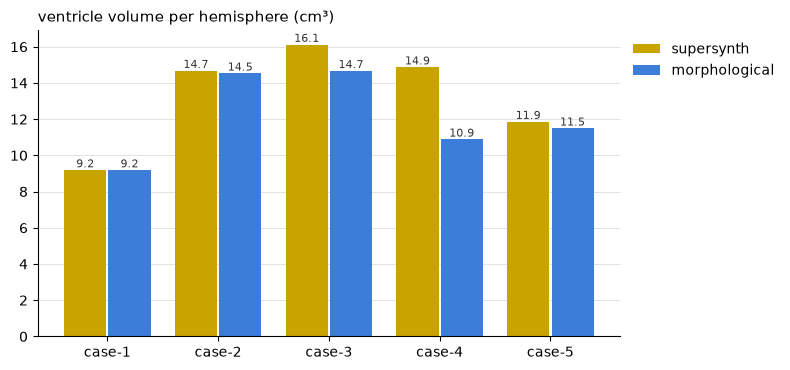

In [9]:
df = pd.DataFrame([ROWS[c] for c in CASES]).set_index("case").astype(float).round(3)
display(df)

fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(len(df)); w = 0.38
b1 = ax.bar(x - w / 2 - 0.01, df["supersynth ventricle (cm3)"], w, color="#c9a400", label="supersynth")
b2 = ax.bar(x + w / 2 + 0.01, df["morphological ventricle (cm3)"], w, color="#3b7dd8", label="morphological")
ax.bar_label(b1, fmt="%.1f", fontsize=8, color="#333"); ax.bar_label(b2, fmt="%.1f", fontsize=8, color="#333")
ax.set_xticks(x, df.index)
ax.set_title("ventricle volume per hemisphere (cm³)", loc="left", fontsize=11)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
ax.grid(axis="y", color="#ddd", linewidth=0.6); ax.set_axisbelow(True)
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout(); plt.show()